In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
from shapely.geometry import Point, Polygon
import pycno

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, ConnectionPatch

from matplotlib.offsetbox import AnchoredText
from matplotlib import cm

import glob
from pathlib import Path
import pickle

tab10 = cm.get_cmap("tab10").colors
tab20b = cm.get_cmap("tab20b").colors
tab20c = cm.get_cmap("tab20c").colors
tab20 = cm.get_cmap("tab20").colors
Set2 = cm.get_cmap("Set2").colors
Dark2 = cm.get_cmap("Dark2").colors
Paired = cm.get_cmap("Paired").colors

biome_colors = {'Boreal Forests/Taiga':tab20[1],'Tundra':tab20c[17],'Deserts & Xeric Shrublands':tab20b[10],
               'Mediterranean Forests, Woodlands & Scrub':tab20b[8],'Montane Grasslands & Shrublands':Set2[5],
               'Flooded Grasslands & Savannas':tab20[5],'Temperate Grasslands, Savannas & Shrublands':Set2[4],
               'Tropical & Subtropical Grasslands, Savannas & Shrublands':tab20[17],
               'Temperate Broadleaf & Mixed Forests':(0.2,0.4,0),'Tropical & Subtropical Moist Broadleaf Forests':tab20[4],
               'Tropical & Subtropical Dry Broadleaf Forests':tab20[16],'Temperate Conifer Forests':Paired[11],
                'Tropical & Subtropical Coniferous Forests':tab20b[5],'Mangrove':[0.27,0.28,0.02],'Lake':[0,0,1],
                'Rock/Ice':[1,1,1]}

biome_dict = {'Boreal Forests/Taiga': 6,'Deserts & Xeric Shrublands': 13,'Flooded Grasslands & Savannas': 9,
 'Mediterranean Forests, Woodlands & Scrub': 12,'Montane Grasslands & Shrublands': 10,
 'Temperate Broadleaf & Mixed Forests': 4,'Temperate Conifer Forests': 5,'Temperate Grasslands, Savannas & Shrublands': 8,
 'Tropical & Subtropical Coniferous Forests': 3,'Tropical & Subtropical Dry Broadleaf Forests': 2,
 'Tropical & Subtropical Grasslands, Savannas & Shrublands': 7,'Tropical & Subtropical Moist Broadleaf Forests': 1,'Tundra': 11,
 'Lake': 98,'Rock/Ice': 99,'Mangrove': 14}

# Color and marker dictionary for land covers
lc_dict = {'Broadleaf deciduous forest':{'mkr':'.','clr':'r','htch':'/'},
           'Broadleaf evergreen or semi-deciduous forest':{'mkr':'P','clr':'r','htch':'|'},
           'Broadleaf forest regularly flooded (fresh-brackish water)':{'mkr':'^','clr':'r','htch':'-'},
           'Broadleaf forest-shrubland permanently flooded (saline water)':{'mkr':'s','clr':'r','htch':'\|'},
           'Needleleaf deciduous forest':{'mkr':'*','clr':'blue','htch':'\\'},
           'Needleleaf evergreen forest':{'mkr':'H','clr':'blue','htch':'+'},
           'Mixed broadleaf and needleleaf deciduous forest':{'mkr':'X','clr':'purple','htch':'O'},
           'Mixed broadleaf and needleleaf evergreen forest':{'mkr':'p','clr':'purple','htch':'OO'},
           'Cropland':{'mkr':'v','clr':'darkgray','htch':'...'},
           'Mosaic cropland (50-70%)/vegetation (20-50%)':{'mkr':'<','clr':'darkgray','htch':'..'},
           'Mosaic vegetation (50-70%)/cropland (20-50%)':{'mkr':'>','clr':'darkgray','htch':'.'},
           'Grassland':{'mkr':'o','clr':[0,1,0],'htch':'**'},
           'Mosaic grassland (50-70%)/forest-shrubland (20-50%)':{'mkr':'2','clr':[1,0.92,0.05],'htch':'*o'},
           'Mosaic forest-shrubland (50-70%)/grassland (20-50%)':{'mkr':'1','clr':[1,0.92,0.05],'htch':'o*'},
           'Shrubland':{'mkr':'D','clr':'orange','htch':'oo'},
           'Shrubland-grassland regularly flooded':{'mkr':'d','clr':'orange','htch':'o-'},
           'Sparse vegetation':{'mkr':'x','clr':'white','htch':''}}

MOY_bins = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30,31])
MOY = MOY_bins[:-1]

In [3]:
df =  pd.read_csv('Rx_Master/Rx_MASTER_v2025-02-07.csv',low_memory=False)

In [7]:
# Read in CSV and set index to unique ID
# df =  pd.read_csv('Rx_Master/Rx_MASTER_v2024-11-29.csv',low_memory=False)
# df.drop(df.columns[0],axis='columns',inplace=True)
# df.rename(columns={"Biome": "Biome (Olson)","Ecoregion": "Ecoregion (Olson)"},inplace=True)
# Add day of year column for seasonal analysis
# df['DOY'] = pd.DatetimeIndex(df['Date'].values).dayofyear

# Add alphabetized biome codes from ecoregion shapefile (will need for plotting biomes later)
# df['BIOME CODE'] = None
# biome_codes = [6,13,9,12,10,4,5,8,3,2,7,1,11]
# i=0
# for biome in np.unique(df['Biome'].dropna()):
#     df.loc[df['Biome']==biome,'BIOME CODE'] = biome_codes[i]
#     i+=1
    
FWIs = [i for i in df.columns if 'ERA5' in i]
countries = np.unique(df['Country'])

MOY_bins = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30,31])
MOY = MOY_bins[:-1]
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# lc_groups = [[i for i in lc_dict.keys() if 'Broadleaf' in i],
#             [i for i in lc_dict.keys() if 'Needleleaf' in i],
#             [i for i in lc_dict.keys() if 'Cropland' in i or 'cropland' in i],
#             [i for i in lc_dict.keys() if 'Grassland' in i or 'grassland' in i and 'Shrubland' not in i],
#             [i for i in lc_dict.keys() if 'Shrubland' in i],
#             [i for i in lc_dict.keys() if 'Sparse' in i]]
fuelbeds = np.unique(df['Fuelbed Classification (GFD-FCCS)'].dropna())
lc_groups = [[i for i in fuelbeds if 'Broadleaf Deciduous Forest' in i],
            [i for i in fuelbeds if 'Broadleaf Evergreen or Semi-' in i],
            [i for i in fuelbeds if 'Broadleaf Forest' in i],
            [i for i in fuelbeds if 'Mixed Broadleaf' in i],
            [i for i in fuelbeds if 'Needleleaf Deciduous Forest' in i and 'Broadleaf' not in i],
            [i for i in fuelbeds if 'Needleleaf Evergreen Forest' in i and 'Broadleaf' not in i],
            [i for i in fuelbeds if 'Cropland:' in i],
            [i for i in fuelbeds if 'Mosaic Cropland (50-70%)' in i],
            [i for i in fuelbeds if 'Mosaic Vegetation (50-70%)' in i],
            [i for i in fuelbeds if 'Mosaic Forest-Shrubland (50-70%)' in i],
            [i for i in fuelbeds if 'Mosaic Grassland (50-70%)' in i],
            [i for i in fuelbeds if 'Grassland' == i],
            [i for i in fuelbeds if 'Shrubland' in i and '-' not in i],
            [i for i in fuelbeds if 'Shrubland-Grassland' in i],
            [i for i in fuelbeds if 'Sparse' in i]]
lc_classes = ['Broadleaf Deciduous Forest','Broadleaf Evergreen or Semi-Deciduous Forest',
              'Flooded Broadleaf Forest','Mixed Broadleaf and Needleleaf Forest',
              'Needleleaf Deciduous','Needleleaf Evergreen',
              'Cropland','Mosaic Cropland (50-70%)/Vegetation (20-50%)','Mosaic Vegetation (50-70%)/Cropland (20-50%)',
              'Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)','Mosaic Grassland (50-70%)/Forest-Shrubland (20-50%)',
              'Grassland','Shrubland','Flooded Shrubland-Grassland','Sparse Vegetation']
i = 0
for group in lc_groups:
    for lc in group:
        df.loc[df['Fuelbed Classification (GFD-FCCS)']==lc,'Fuelbed Group'] = lc_classes[i]
    i+=1

In [468]:
df.groupby(['Country','Biome (Olson)']).size().to_csv('summary_table_country_biome_GlobalRx.csv')

### Create Area Burned (Ha) histograms

In [469]:
BA_idx = df['Area Burned (Ha)'].dropna().index
BA_df = df.loc[BA_idx]

BA_countries = np.unique(BA_df['Country'].dropna())
bins = [0,0.5,1,5,10,50,100,500,1000,5000,10000,50000,100000,500000,1000000,2000000]
BA_hists = [np.histogram(BA_df.groupby(['Country']).get_group(country)['Area Burned (Ha)'],bins=bins)[0] for country in BA_countries]

bin_names = ["{:,}".format(bins[i])+'-'+"{:,}".format(bins[i+1])+' Ha' for i in range(len(bins)-1)]
BA_hist_df = pd.DataFrame(BA_hists,index=BA_countries,columns=bin_names)
BA_hist_df.to_excel('summary_table_burned_area_hist_GlobalRx.xlsx')

In [305]:
######### TEST BED #########

country = 'United States'
wf_df = pd.read_csv(glob.glob('Wildfire_Areas/*'+country+'*')[0])

mo_dict = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
          'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}
wf_df['Month'] = wf_df['Month'].map(mo_dict)

wf_mo = 5
wf_yr = 2003

wf_idx = (wf_df['Month']==wf_mo) & (wf_df['Year']==wf_yr)
wf_size = wf_df.loc[wf_idx,'Fire Size [ha]']
Rx_idx = (df['Month']==wf_mo) & (df['Year']==wf_yr) & (df['Country']==country)

# df['Wildfire Flag'] = np.nan
df.loc[Rx_idx,'Wildfire Flag'] = df.loc[Rx_idx,'Area Burned (Ha)'].astype(float)>wf_size.values[0]

wf_mdn = wf_df.loc[wf_df['Month']==wf_mo,'Fire Size [ha]'].median()
rest_idx = (df['Country']==country) & (df['Month']==wf_mo) & (df['Year']<2002) | (df['Year']>2023)
df.loc[rest_idx,'Wildfire Flag'] = df.loc[rest_idx,'Area Burned (Ha)'].astype(float)>wf_mdn

### Create Wildfire Flag based on MODIS Data

In [312]:
countries = np.unique(df['Country'])
# For every country, extract MODIS average wildfire size monthly time series
for country in countries:
    # Read in MODIS average wildfire size monthly time series
    wf_df = pd.read_csv(glob.glob('Wildfire_Areas/*'+country+'*')[0])
    mo_dict = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
          'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}
    wf_df['Month'] = wf_df['Month'].map(mo_dict)
    
    wf_mos = np.unique(wf_df['Month'])
    wf_yrs = np.unique(wf_df['Year'])
    
    # Iterate through each month
    for wf_mo in wf_mos:
        for wf_yr in wf_yrs:
            # Find the average wildfire size for given year and month in MODIS time series
            wf_idx = (wf_df['Month']==wf_mo) & (wf_df['Year']==wf_yr)
            wf_size = wf_df.loc[wf_idx,'Fire Size [ha]'].values[0]
            
            # Find all records with same month, year, and country as average wildfire size
            Rx_idx = (df['Month']==wf_mo) & (df['Year']==wf_yr) & (df['Country']==country)
            

            Rx_idx = (df['Month']==wf_mo) & (df['Year']==wf_yr) & (df['Country']==country)
            # Create flag for all records in given month, year, and country
            df.loc[Rx_idx,'Wildfire Flag'] = df.loc[Rx_idx,'Area Burned (Ha)'].astype(float)<wf_size
    
        # For all burn records that aren't in MODIS period, use whole period median as threshold for those years
        
        # Whole period median for given country
        wf_mdn = wf_df.loc[wf_df['Month']==wf_mo,'Fire Size [ha]'].median()
        
        # Find all records within GlobalRx in given country, month, and year outside 2002-2023
        rest_idx = (df['Country']==country) & (df['Month']==wf_mo) & (df['Year']<2002) | (df['Year']>2023)
        df.loc[rest_idx,'Wildfire Flag'] = df.loc[rest_idx,'Area Burned (Ha)'].astype(float)<wf_mdn

In [2318]:
country = 'United States'
try:
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
except:
    # If shapefile doesn't have a pre-existing CRS
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')

# Find wildfires only within country
# country_wf_shp = gpd.sjoin(country_shp,wf_shp)
# country_wf = wf_shp.loc[country_wf_shp['index_right'].values]

In [203]:
FTM_df = pd.read_csv('FTM.csv')
USGS_df = pd.read_csv('USGS_duplicates_cleaned.csv')
MTBS_df = pd.read_csv('MTBS_cleaned_duplicates.csv')
NFPORS_df = pd.read_csv('NFPORS_cleaned_duplicates.csv')
NFPORS_df.rename(columns={'Area Burned':'Area Burned (Ha)'},inplace=True)
NFPORS_df.rename(columns={'Link to Data Repository':'Data Repository'},inplace=True)
NFPORS_df.drop(['Area Burned Units'],axis=1,inplace=True)

In [204]:
US_master = pd.concat([USGS_df,MTBS_df,NFPORS_df,FTM_df])
US_master = US_master[US_master['Year']<2024]
US_master.drop_duplicates(subset=['Latitude','Longitude','Year','Month','Day'],inplace=True)
US_master.reset_index(inplace=True)
US_master.drop(columns=['index'],inplace=True)

In [227]:
def create_globalrx_id(row):
    lat_prefix = "N" if row['Latitude'] >= 0 else "S"
    lon_prefix = "E" if row['Longitude'] >= 0 else "W"

    # Formatting latitude and longitude with specified precision and length
    lat_value = f"{abs(row['Latitude']):07.4f}"  # Total length = 8
    lon_value = f"{abs(row['Longitude']):8.4f}"  # Total length = 9

    date_str = row['datestring']
    return f"Rx{date_str}-{lat_prefix}{lat_value}-{lon_prefix}{lon_value}"

In [222]:
US_master['datestring'] = US_master['Year'].astype(int).astype(str)+US_master['Month'].astype(int).astype(str).apply(lambda x: '0'+x if len(x)<2 else x)+US_master['Day'].astype(int).astype(str).apply(lambda x: '0'+x if len(x)<2 else x)

In [237]:
US_master.drop_duplicates(subset='ID',inplace=True)
# len(US_master)

In [229]:
US_master['ID'] = US_master.apply(create_globalrx_id, axis=1)

In [245]:
temp_ids = []
for i in US_master.index:
    temp_id = [
    str(np.round(US_master.loc[i,'Latitude'],2))+
    str(np.round(US_master.loc[i,'Longitude'],2))+'-'+
    str(US_master.loc[i,'Year'].astype(int))+'-'+
    str(US_master.loc[i,'Month'].astype(int))+'-'+
    str(US_master.loc[i,'Day'].astype(int))]
    temp_ids.append(temp_id[0])
    
US_master['temp_id'] = temp_ids
# US_master.drop_duplicates(subset=['temp_id'],inplace=True)

,ID,Latitude,Longitude,Year,Month,Day,Time,Country,State/Province,Agency/Organisation,Timestamp of Update,Data Repository,Citation,Area Burned (Ha),Burn Objective,Link to Data Repository,Date,temp_id,datestring
31951,Rx20000916-N19.7442-W155.3833,19.744225,-155.38325,2000,9.0,16.0,NaN,United States,Hawaii,United States Geological Survey (USGS),2024-12-09 16:59:58.140635,https://doi.org/10.5066/P9ZXGFY3,"Welty, J.L., and Jeffries, M.I., 2021, Combine...",192.870116,NaN,NaN,NaN,19.74-155.38-2000-9-16,20000916


In [262]:
pd.set_option('display.max_rows',None)
pd.reset_option('max_rows')
US_master.groupby(['temp_id','Data Repository']).size()[US_master.groupby(['temp_id','Data Repository']).size()>1]

In [134]:
df[df['Country']=='United States'].groupby(['Data Repository']).size()

Data Repository
https://doi.org/10.5066/P9ZXGFY3                                     23570
https://iftdss.firenet.gov/                                          10354
https://www.fs.usda.gov/rds/archive/catalog/RDS-2020-0001-2             80
https://www.sciencebase.gov/catalog/item/5e541969e4b0ff554f753113     1445
dtype: int64

In [264]:
US_df = pd.read_csv('Rx_Master/US_master.csv',low_memory=False)

In [260]:
US_master.groupby(['Data Repository']).size()

Data Repository
https://doi.org/10.5066/P9ZXGFY3                               31136
https://iftdss.firenet.gov/                                     9132
https://www.fs.usda.gov/rds/archive/catalog/RDS-2020-0001-2       79
https://www.mtbs.gov/direct-download                            1979
dtype: int64

In [240]:
US_master.to_csv('US_master.csv',index=False)

In [244]:
USGS_df

Agency/Organisation
United States Geological Survey (USGS)    32232
dtype: int64

In [2762]:
drop_idxs = []
for i in range(0,len(NFPORS_dup)):
    dup_lat = np.round(NFPORS_dup.loc[i,'Latitude'],6)
    dup_lon = np.round(NFPORS_dup.loc[i,'Longitude'],6)
    dup_date = pd.to_datetime(NFPORS_dup.loc[i,'Date'])
    
    drop_idx = df[(np.round(df.loc[:,'Latitude'],6)==dup_lat)&
                  (np.round(df.loc[:,'Longitude'],6)==dup_lon)&
                 df['Date']==dup_date].index
    drop_idxs.append(drop_idx)
#     df.drop(drop_idx,inplace=True) # Shit, this deletes duplicates and the date I need to keep
drop_idxs = np.concatenate(drop_idxs).flatten()

In [2768]:
len(np.unique(np.concatenate(drop_idxs).flatten()))

1896

In [2548]:
USGS_df = pd.read_csv('Process_Rx/USA/USGS_pt2.csv')
USGS_dates = pd.DatetimeIndex(USGS_df['Year'].astype(str)+'-'+USGS_df['Month'].astype(str)+'-'+USGS_df['Day'].astype(str))
USGS_df['DOY'] = USGS_dates.dayofyear
USGS_df['datestring'] = USGS_dates.strftime('%Y%m%d')
USGS_df['ID'] = np.array([create_globalrx_id(USGS_df.iloc[i]) for i in range(0,len(USGS_df))])
USGS_df.rename(columns={'Agency / Organisation':'Agency/Organisation'},inplace=True)
USGS_df.rename(columns={'Link to Data Repository':'Data Repository'},inplace=True)
USGS_df.drop(['datestring','Area Burned Units','Raw data filename(s)'],axis=1,inplace=True)

In [2594]:
USGS_df.to_csv('USGS_pt2_v2.csv',index=False)

In [2596]:
USGS_master = pd.read_csv('Rx_Master/USGS_pt2_master_.csv')
USGS_master.drop(['Date'],axis=1,inplace=True)

In [2621]:
df_master = pd.concat([df2,USGS_master])

In [2623]:
df_master.to_csv('Rx_Master/Rx_MASTER_v2024-12-05.csv',index=False)

/tmp/ipykernel_7186/1166661069.py:6: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(labels=bin_names,rotation=90);


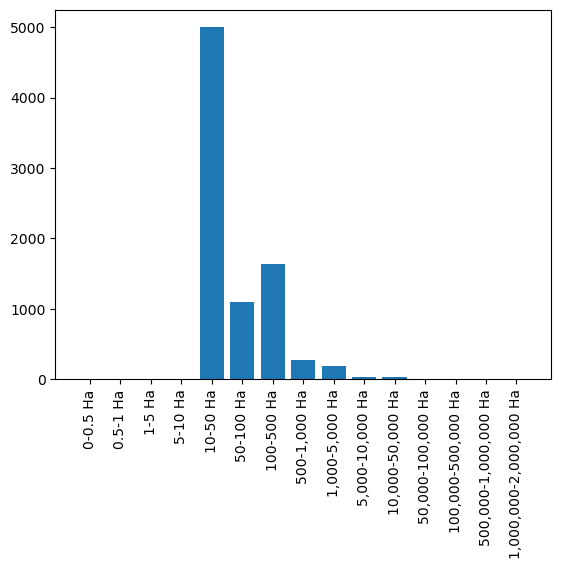

In [246]:
country_BAs = country_wf['area_ha'].values
counts = np.histogram(country_BAs,bins=bins)[0]

fig,ax = plt.subplots()
ax.bar(bin_names,counts)
ax.set_xticklabels(labels=bin_names,rotation=90);

In [279]:
BA_countries = np.unique(df.dropna(subset='Area Burned (Ha)')['Country'])
for year in range(2002,2024):
    wf_shp = gpd.read_file(glob.glob('GLOBFIRE*/*'+str(year)+'.shp')[0])
    for countries in BA_countries:
        try:
            country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
        except:
            # If shapefile doesn't have a pre-existing CRS
            country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')

        # Find wildfires only within country
        country_wf_shp = gpd.sjoin(country_shp,wf_shp)
        country_wf = wf_shp.loc[country_wf_shp['index_right'].values]
        country_BAs = country_wf['area_ha'].values
        country_BA_99 = np.nanpercentile(country_BAs,99)
        
        df.loc[(df['Country']==country)&(df['Year']==year)&(df['Area Burned (Ha)']>country_BA_99),'Wildfire Flag'] = True

/gpfs/home/zna22eeu/.conda/envs/geo_env2/lib/python3.8/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)
/gpfs/home/zna22eeu/.conda/envs/geo_env2/lib/python3.8/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


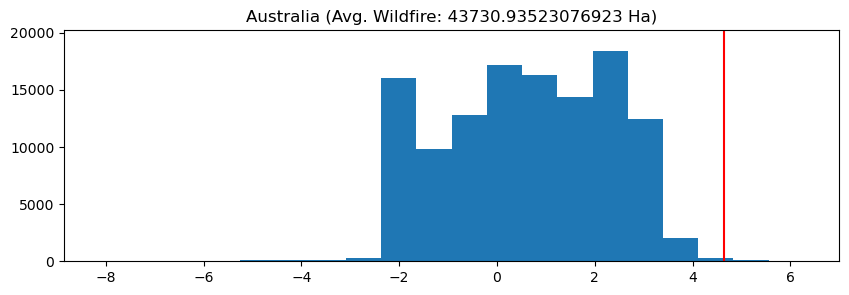

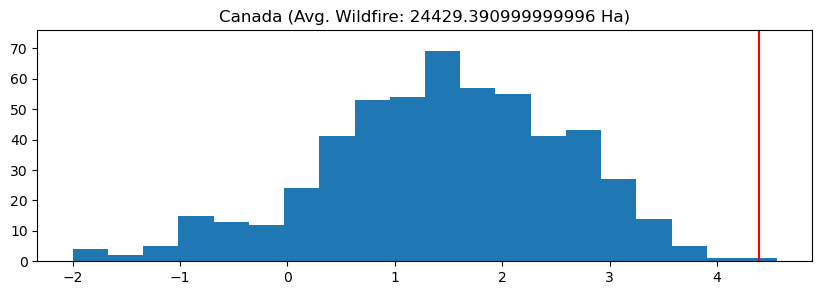

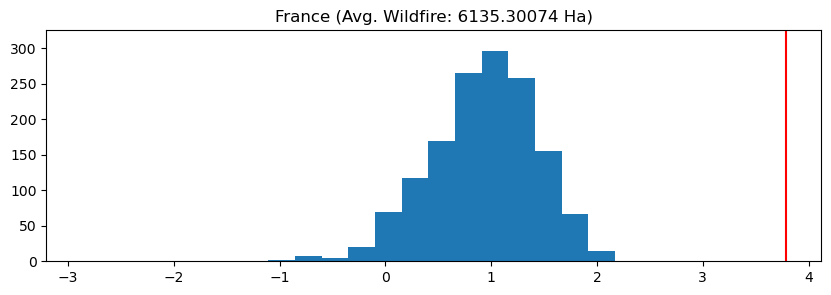

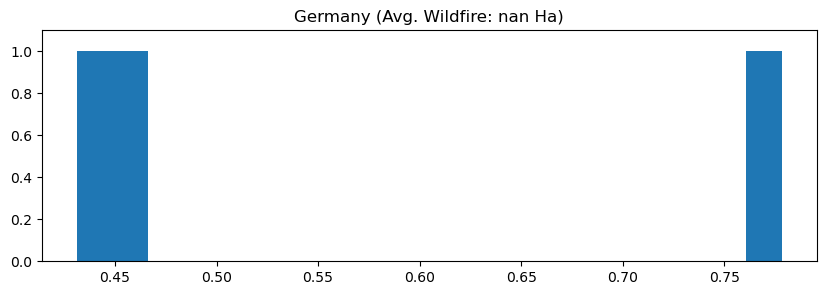

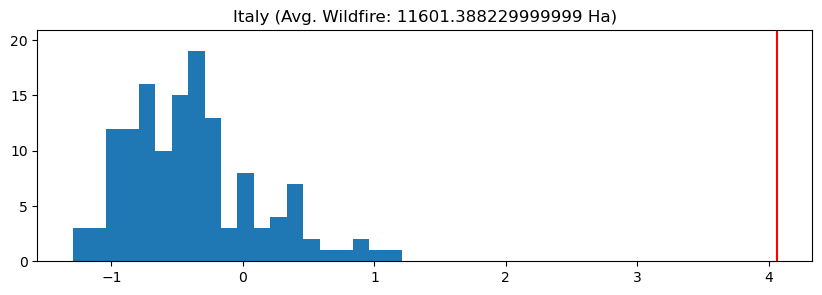

...

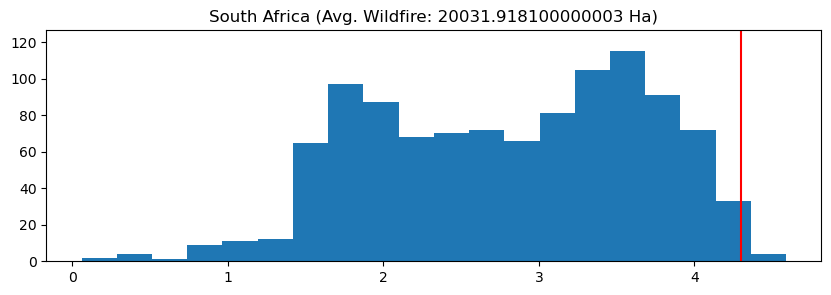

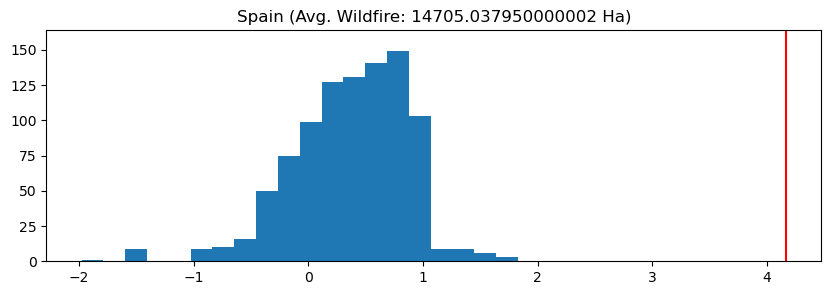

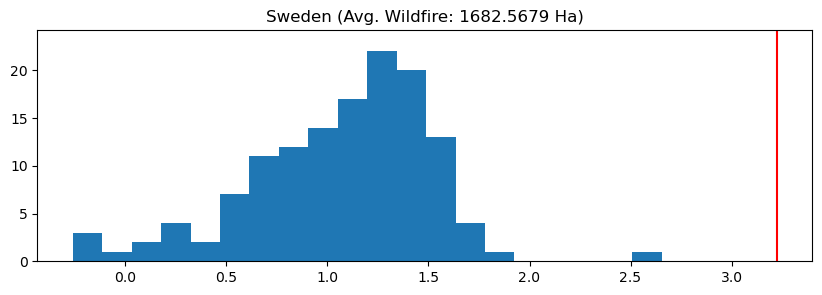

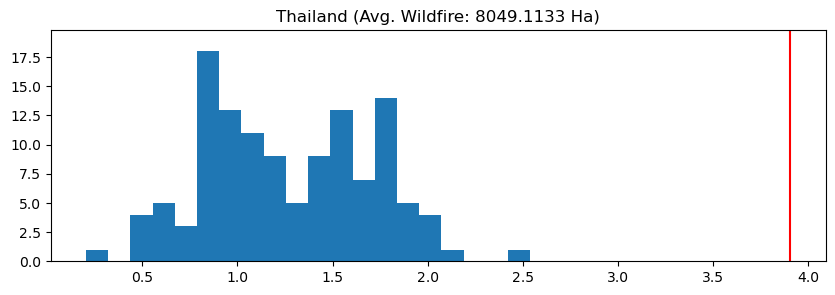

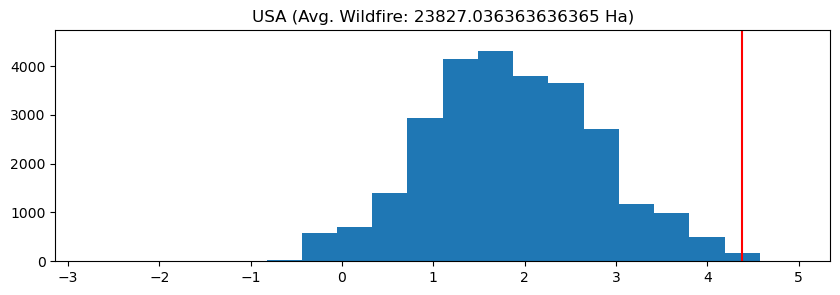

In [189]:
wf_avgs = []
countries = np.unique(df['Country'])
for country in countries:
    wf_df = pd.read_csv(glob.glob('Wildfire_Areas/*'+country+'*')[0])
    country_df = df[df['Country']==country]
    country_df = country_df[~(country_df['Area Burned (Ha)'].astype(float)==0)]
    
    if len(country_df[~country_df['Area Burned (Ha)'].isnull()])==0:
        continue
    if country=='USA':
        wf_df = avg_df[avg_df['Entity']=='United States'].set_index('Year')
    else:
        wf_df = avg_df[avg_df['Entity']==country].set_index('Year')
    yrs = [year for year in wf_df.index if year in np.unique(country_df['Year'])]
    wf_avg = wf_df.loc[yrs,'Annual area burnt per wildfire'].mean()
    wf_avgs.append(wf_avg)
    fig,ax= plt.subplots(figsize=(10,3))
    ax.set_title(country+' (Avg. Wildfire: '+str(wf_avg)+' Ha)');
    n,bins,patches=ax.hist(np.log10(country_df['Area Burned (Ha)'].astype(float).dropna()),bins=20)
    ax.vlines(x=np.log10(wf_avg),ymin=0,ymax=len(country_df),color='red')
    ax.set_ylim([0,n.max()*1.1])
    xticks = ['10$^'+str(len(str(10**i))-2)+'$' for i in range(len(ax.get_xticklabels()))]
    ax.set_xticklabels(xticks)

### Specify country and extract country specs

In [3]:
country = 'Australia'
country_df = df[df['Country']==country]
tot_fires = len(country_df)

biomes = np.unique(country_df['Biome (Olson)'].dropna().values)
fire_types = np.unique(country_df['Fire Type'].dropna().values)
# desigs = np.unique(country_df['Protected Area Designation (WDPA)'].dropna().values)
eco_names = np.unique(country_df['Ecoregion (Olson)'].dropna().values)
# gov_types = np.unique(country_df['Protected Area Governance (WDPA)'].dropna().values)
# names = np.unique(country_df['Protected Area Name (WDPA)'].dropna().values)
# land_covers = np.unique(country_df['Land Cover (Pettinari & Chuvieco)'].dropna().values)
# land_covers = [i for i in lc_dict.keys() if i in np.unique(country_df['Land Cover (Pettinari & Chuvieco)'].dropna().values)]

In [4]:
pd.set_option('display.max_rows',None)
pd.reset_option('max_rows')

### Fire Count by Season and Biome

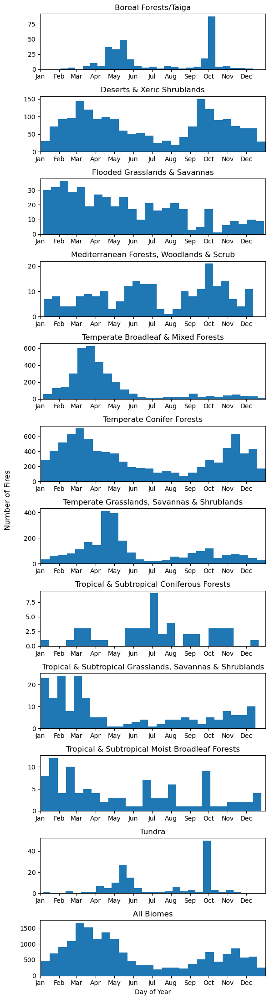

In [54]:
# Fire count by season and biome
MOY = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30])
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig,ax = plt.subplots(len(biomes)+1,1,figsize=(6,len(biomes)*2))
i=0
for biome in biomes:
    counts = country_df[country_df['Biome (Olson)']==biome]['DOY']
    ax[i].hist(counts,bins=26)
    ax[i].set_xlim([1,365])
    ax[i].set_title(biome)
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months)
#     ax[i].set_yticks([])
    i+=1
        
ax[len(biomes)].hist(country_df['DOY'],bins=26)
ax[len(biomes)].set_xlim([1,365])
ax[len(biomes)].set_xticks(MOY)
ax[len(biomes)].set_xticklabels(months)
ax[len(biomes)].set_title('All Biomes')
ax[len(biomes)].set_xlabel('Day of Year')
        
fig.supylabel('Number of Fires')
plt.tight_layout()

plt.savefig('fire_count_seasonality_by_biome_'+country+'.png',bbox_inches='tight')

In [29]:
np.histogram(country_df['DOY'],bins=np.append(MOY,365))[0]

array([283, 535, 283,  26,   0,   0,   0,   0,   0,   4, 131, 186])

### Fire Count by Burn Reason

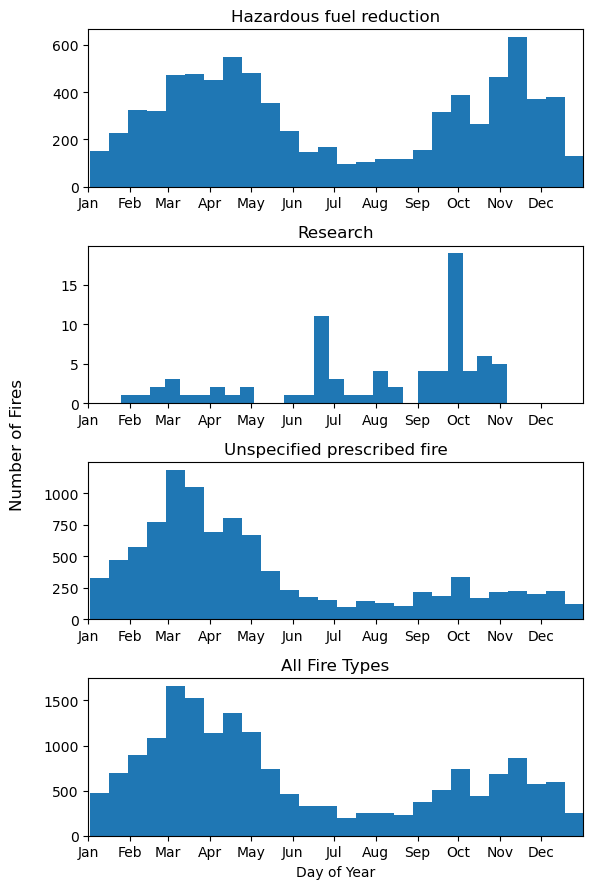

In [23]:
# Fire count by season and biome
specs = fire_types
spec_name = 'Fire Type'
MOY = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30])
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig,ax = plt.subplots(len(specs)+1,1,figsize=(6,len(specs)*3))
i=0
for spec in specs:
    counts = country_df[country_df[spec_name]==spec]['DOY']
    ax[i].hist(counts,bins=26)
    ax[i].set_xlim([1,365])
    ax[i].set_title(spec)
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months)
#     ax[i].set_yticks([])
    i+=1
        
ax[len(specs)].hist(country_df['DOY'],bins=26)
ax[len(specs)].set_xlim([1,365])
ax[len(specs)].set_xticks(MOY)
ax[len(specs)].set_xticklabels(months)
ax[len(specs)].set_title('All '+spec_name+'s')
ax[len(specs)].set_xlabel('Day of Year')
        
fig.supylabel('Number of Fires')
plt.tight_layout()

plt.savefig('fire_count_seasonality_by_'+spec_name.replace(' ','_')+'_'+country+'.png',bbox_inches='tight')

In [91]:
np.histogram(country_df[country_df['Fire Type']=='Unspecified prescribed fire']['DOY'],bins=np.append(MOY,365))

(array([ 1,  0,  0,  3, 36, 40, 32, 18,  4,  0,  0,  0]),
 array([  0,  31,  59,  90, 120, 151, 181, 212, 243, 273, 304, 334, 365]))

### Fire Count by Land Cover

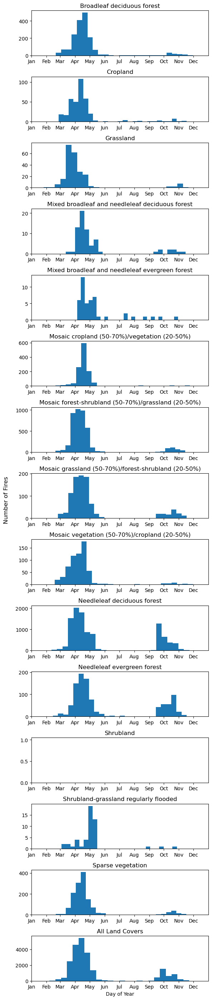

In [4]:
# Fire count by month and land cover
fig,ax = plt.subplots(len(land_covers)+1,1,figsize=(6,len(land_covers)*2))
i=0
for lc in land_covers:
    counts = country_df[country_df['Land Cover (Pettinari & Chuvieco)']==lc]['DOY']
    ax[i].hist(counts,bins=26)
    ax[i].set_xlim([1,365])
    ax[i].set_title(lc)
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months)
#     ax[i].set_yticks([])
    i+=1
        
ax[len(land_covers)].hist(country_df['DOY'],bins=26)
ax[len(land_covers)].set_xlim([1,365])
ax[len(land_covers)].set_xticks(MOY)
ax[len(land_covers)].set_xticklabels(months)
ax[len(land_covers)].set_title('All Land Covers')
ax[len(land_covers)].set_xlabel('Day of Year')
        
fig.supylabel('Number of Fires')
plt.tight_layout()

plt.savefig('fire_count_seasonality_by_land_cover_'+country+'.png',bbox_inches='tight')

In [29]:
np.histogram(country_df['DOY'],bins=np.append(MOY,365))[0]

array([ 86, 181, 341,  93,  71,  17,  40,  25,  52,  46,  60,  39])

### Fire Burned Area by Season and Biome

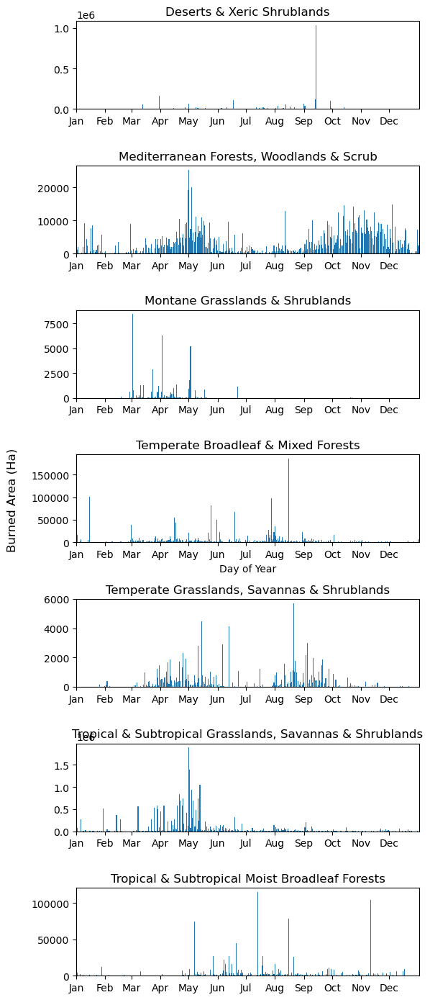

In [9]:
fig,ax = plt.subplots(len(biomes),1,figsize=(6,len(biomes)*2))
i=0
for biome in biomes:
    BA = country_df[country_df['Biome (Olson)']==biome]['Area Burned (Ha)']
    DOY = country_df[country_df['Biome (Olson)']==biome]['DOY']
    ax[i].bar(DOY,BA)
    ax[i].set_xlim([1,366])
    ax[i].set_title(biome)
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months)
    i+=1
    
    if i==3:
        ax[i].set_xlabel('Day of Year')
        
fig.supylabel('Burned Area (Ha)')
plt.tight_layout()

# plt.savefig('fire_BA_seasonality_by_biome_'+country+'.png',bbox_inches='tight')

### Country and Ecoregion Shapefiles

In [268]:
# Country shapefile
try:
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
except:
    # If shapefile doesn't have a pre-existing CRS
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')
country_shp.set_index(country_shp.columns[0],inplace=True)
bounds = country_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]

# Ecoregions shapefile
eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
eco_shp.set_index('OBJECTID',inplace=True)

# Find ecoregions only within country
country_eco_shp = gpd.sjoin(country_shp,eco_shp)

# Index of ecoregions in country in original ecoregion shapefile
eco_idx = np.unique(country_eco_shp['index_right'])

# Extract ecoregions only within country
country_eco = eco_shp.loc[eco_idx]

# Fires in each administrative boundary of country
fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(country_df['Longitude'],country_df['Latitude'])]})
fire_pts.crs = 'EPSG:4326'
fire_shp = gpd.sjoin(country_shp,fire_pts)

# Add a biome and land cover columns to administrative boundary dataframe
fire_shp['Month'] = country_df['Month'].iloc[fire_shp['index_right'].values].values
fire_shp['DOY'] = country_df['DOY'].iloc[fire_shp['index_right'].values].values
fire_shp['Biome (Olson)'] = country_df['Biome (Olson)'].iloc[fire_shp['index_right'].values].values
# fire_shp['Land Cover (Pettinari & Chuvieco)'] = country_df['Land Cover (Pettinari & Chuvieco)'].iloc[fire_shp['index_right'].values].values
fire_shp['Area Burned (Ha)'] = country_df['Area Burned (Ha)'].iloc[fire_shp['index_right'].values].values

# Fires in each ecoregion (should be same length as country_df)
fire_eco_shp = gpd.sjoin(eco_shp,fire_pts)
fire_eco_shp['Biome (Olson)'] = country_df['Biome (Olson)'].iloc[fire_eco_shp['index_right'].values].values
# fire_eco_shp['Land Cover (Pettinari & Chuvieco)'] = country_df['Land Cover (Pettinari & Chuvieco)'].iloc[fire_eco_shp['index_right'].values].values

KeyError: 'DOY'

In [136]:
country_df = df[df['Country']=='Australia']

In [141]:
idx = [True if 'Protection' in str(i) or 'Bushfire' in str(i) else False for i in country_df['Burn Objective']]

In [144]:
country_df.loc[idx,'Burn Objective']

48521         Strategic Protection,Biodiversity Management
48527                                 Strategic Protection
48528                                 Strategic Protection
48531                                 Strategic Protection
48535         Strategic Protection,Biodiversity Management
                               ...                        
60503         Strategic Protection,Biodiversity Management
60505         Strategic Protection,Biodiversity Management
60506    Strategic Protection,Biodiversity Management,R...
60507         Strategic Protection,Biodiversity Management
60508         Strategic Protection,Biodiversity Management
Name: Burn Objective, Length: 2700, dtype: object

### Fire count by month and administrative districts

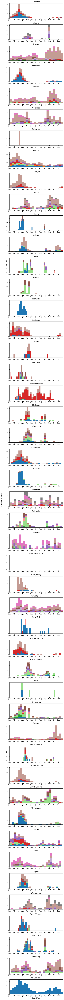

In [11]:
# Set land cover colors
tab10 = cm.get_cmap("tab20").colors
lc_clrs = {}
i=0
for lc in land_covers:
    lc_clrs[lc] = tab10[i]
    i+=1

adm = 'STATE'
admins = np.unique(fire_shp[adm].dropna())
fig,ax = plt.subplots(len(admins)+1,1,figsize=(6,len(admins)*2))
i=0
for admin in admins:
    admin_shp = fire_shp[fire_shp[adm]==admin]
    admin_lcs = np.unique(admin_shp['Land Cover (Pettinari & Chuvieco)'].dropna())
    lc_counts = []
    colors = []
    for lc in admin_lcs:
        lc_count = admin_shp[admin_shp['Land Cover (Pettinari & Chuvieco)']==lc]['DOY']
        lc_counts.append(lc_count)
        colors.append(lc_clrs[lc])
    ax[i].hist(lc_counts,color=colors,stacked=True,bins=26)
    ax[i].set_xlim([1,365])
    ax[i].set_title(admin)
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months)
#     ax[i].set_yticks([])
    i+=1
        
ax[len(admins)].hist(country_df['DOY'],bins=26)
ax[len(admins)].set_xlim([1,365])
ax[len(admins)].set_xticks(MOY)
ax[len(admins)].set_xticklabels(months)
ax[len(admins)].set_title('All Districts')
ax[len(admins)].set_xlabel('Day of Year')
        
fig.supylabel('Number of Fires')
plt.tight_layout()

# plt.savefig('fire_count_seasonality_by_admin_district_'+country+'.png',bbox_inches='tight')

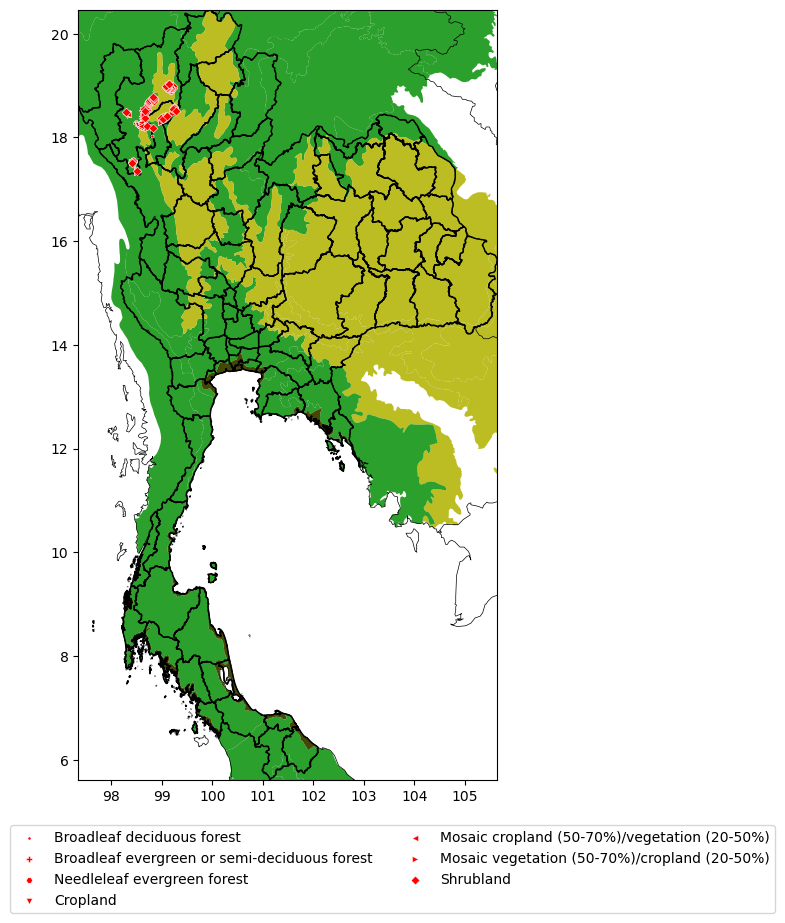

In [14]:
mkrs = ['o','^','s','D','*','p','X','H','.','P','d','v','2','_','|']
for biome in biomes:
    country_eco.loc[country_eco['Biome (Olson)']==biome_dict[biome],'Biome (Olson)'] = biome


fig, ax = plt.subplots(figsize=(10,10))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')
# country_eco.plot(column='Biome (Olson)',cmap=,ax=ax,edgecolor=None,legend=True)
country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=ax,categories=biomes,aspect='equal')
if country == 'USA':
    ax.set_xlim([-125,-67])
    ax.set_ylim([25,50])
else:
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

country_shp.plot(facecolor='none',edgecolor='black',ax=ax)

i=0
for lc in land_covers:
    idx = country_df['Land Cover (Pettinari & Chuvieco)']==lc
    mkr = lc_dict[lc]['mkr']
    clr = lc_dict[lc]['clr']
    if mkr == '1' or mkr == '2':
        lw = 6
        eclr = 'None'
    else:
        lw = 0.4
        eclr = 'black'
    ax.scatter(country_df[idx]['Longitude'],country_df[idx]['Latitude'],marker=mkr,color='r',
               edgecolor='white',linewidth=lw,s=20,label=lc)
    i+=1
    
# box = ax.get_position()
# ax.set_position([box.x0, box.y0 + box.height * 0.1,
#                  box.width, box.height * 0.9])
ax.legend(loc='upper center', bbox_to_anchor=(0.75, -0.05),
          fancybox=True,ncol=2)
# ax.set_title(country,fontsize=32)
# plt.savefig(country+'map_scatter.png',bbox_inches='tight')

<AxesSubplot:>

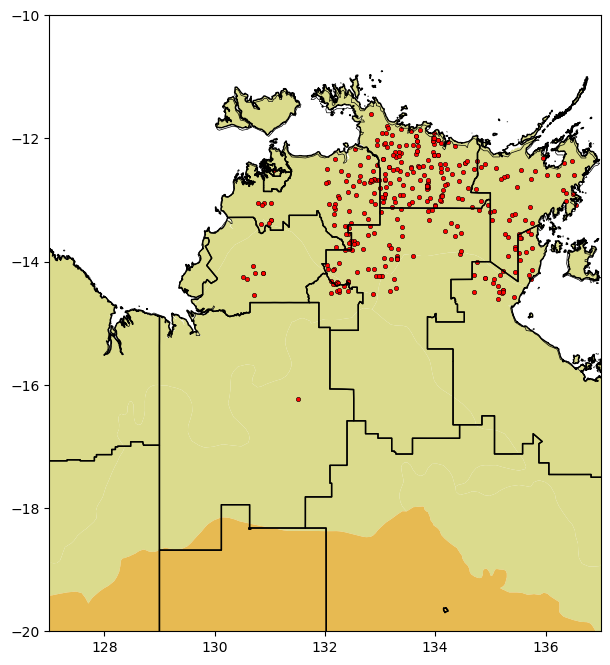

In [12]:
mkrs = ['o','^','s','D','*','p','X','H','.','P','d','v','2','_','|']
htch = ['/','+','.','-','O','x','o','*','|','\|','O.','Ox']
i=0

fig, ax = plt.subplots(figsize=(8,8))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')
country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=ax,edgecolor=None,legend=True,
                legend_kwds={'bbox_to_anchor':(0,0,1,-0.1),'ncol':3})
# country_eco.plot(column='ECO_NAME',cmap='tab20',legend=True,ax=ax,
#                  legend_kwds={'bbox_to_anchor':(0,0,1,-0.1),'ncol':3},alpha=0.7)
# for biome in biomes:
#     mkr = mkrs[i]
#     biome_idx = country_df['Biome (Olson)']==biome
#     biome_lat = country_df[biome_idx]['Latitude']
#     biome_lon = country_df[biome_idx]['Longitude']
    
#     # Color code by day of year
#     biome_DOY = country_df[biome_idx]['DOY']
    
#     country_eco.loc[country_eco['BIOME']==biome_dict[biome]].plot(hatch=htch[i],ax=ax,label=biome,
#                                                                   facecolor='none',edgecolor='gray')
NT_lon = df.loc[df['State/Province']=='Northern Territory','Longitude']
NT_lat = df.loc[df['State/Province']=='Northern Territory','Latitude']
sc = ax.scatter(NT_lon,NT_lat,c='r',s=10,marker='o',edgecolors='k',
                    vmin=0,vmax=365,linewidth=0.4,alpha=1)
i+=1
# DOY colorbar
# cbar = plt.colorbar(sc,ax=ax,fraction=0.015,pad=0.01)
# cbar.set_ticks(MOY)
# cbar.set_ticklabels(months)

# Color code by land cover type
# country_lc = country_df['Land Cover (Pettinari & Chuvieco)']
# Set1 = cm.get_cmap("Set1").colors[0:len(land_covers)]
# colors = dict(zip(land_covers,Set1))
# colors[np.nan] = (1,1,1)

# Land Cover Scatter
# i=0
# for lc in land_covers:
#     country_lc = country_df[country_df['Land Cover (Pettinari & Chuvieco)']==lc]
#     sc = ax.scatter(country_lc['Longitude'],country_lc['Latitude'],
#                     s=50,marker=mkrs[i],edgecolors='black',linewidth=0.5,label=lc)
#     i+=1
# ax.legend(title='Land Cover Types')
    
if country=='USA':
    # Alaska
#     ax.set_xlim([-180,-140])
#     ax.set_ylim([50,71.5])
    # CONUS
    ax.set_xlim([-127,-65])
    ax.set_ylim([25,50])
elif country == 'Portugal':
    ax.set_xlim([-10,-6])
#     ax.set_ylim([36.5,42.5])
    ax.set_xticks([-10,-8,-6])
    ax.tick_params(labelsize=20)
    ax.set_yticks([])
#     ax2 = ax.secondary_yaxis("right")
    ax.set_yticks([36,38,40,42,44])
    ax.tick_params(axis="y", direction="out", length=3,labelsize=20)
    ax.set_ylim([36.5,42.5])
elif country == 'Russia':
    ax.set_xlim([15,180])
    ax.set_ylim([40,80])
elif country == 'Japan':
    ax.set_xlim([128,146])
    ax.set_ylim([30,46])
else:
    ax.set_xlim([127,137])
    ax.set_ylim([-20,-10])
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)
# plt.savefig('Portugal_GlobalRx_burns.png',transparent=True,bbox_inches='tight')

### United States divisions and analysis

In [4]:
np.unique(df['Country'])

array(['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'Italy',
       'Japan', 'Mexico', 'Portugal', 'Russia', 'South Africa', 'Spain',
       'Sweden', 'Thailand', 'United Kingdom', 'United States'],
      dtype=object)

In [5]:
US_df = df[df['Country']=='United States']
country_df = US_df

# Great Plains temperate grasslands + all of Minnesota, Michigan, Wyoming, and Iowa
GP_states = ['Texas','New Mexico','Oklahoma','Missouri','Kansas','Colorado',
        'Nebraska','Iowa','Illinois','Indiana','Wyoming','South Dakota',
        'North Dakota','Montana']
GP_df = country_df.set_index('State/Province').loc[GP_states]
GP_df.reset_index(inplace=True)
GP_df = GP_df.set_index('Biome (Olson)').loc['Temperate Grasslands, Savannas & Shrublands']
GP_df.reset_index(inplace=True)
GP_df = pd.concat([GP_df,(country_df.set_index('State/Province').loc[['South Dakota','Iowa',
                                                                      'Minnesota','Wisconsin',
                                                                      'Michigan']]).reset_index()])
GP_df.drop_duplicates(inplace=True)
GP_df.reset_index(inplace=True)

# South Atlantic Coastal temperate conifer and broadleaf forests
SATL_states = ['Kentucky','Virginia','Arkansas','Tennessee','Maryland',
        'North Carolina','South Carolina','Louisiana','Delaware',
        'Mississippi','Alabama','Georgia','Florida','New Jersey',
        'Oklahoma','Texas','Missouri','Indiana','Ohio','West Virginia',
        'New York','Pennsylvania','Delaware','Illinois','New Hampshire',
        'Massachusetts','Maine']
SATL_df = country_df.set_index('State/Province').loc[SATL_states]
SATL_df.reset_index(inplace=True)
SATL_df = SATL_df.set_index('Biome (Olson)').loc[['Temperate Broadleaf & Mixed Forests','Temperate Conifer Forests',
                                                'Flooded Grasslands & Savannas',
                                                'Tropical & Subtropical Grasslands, Savannas & Shrublands',
                                                'Tropical & Subtropical Coniferous Forests',
                                                'Tropical & Subtropical Moist Broadleaf Forests']]
SATL_df = SATL_df[SATL_df['Longitude']>-100]
SATL_df.drop_duplicates(inplace=True)
SATL_df.reset_index(inplace=True)

# West; all burns not in GP or SATL
W_states = ['Washington','Oregon','Idaho','Montana','Wyoming','California',
             'Nevada','Utah','Colorado','Arizona','New Mexico','Texas']
netID = np.append(SATL_df['ID'].values,GP_df['ID'].values)
W_df = country_df.loc[~country_df.set_index('ID').index.isin(netID)]
W_df = W_df[~(W_df['State/Province']=='Alaska')]
W_df = W_df[~(W_df['State/Province']=='Puerto Rico')]
W_df.drop_duplicates(inplace=True)
W_df.reset_index(inplace=True)

err_IDs = W_df.set_index('State/Province').loc[['Virginia','North Carolina','South Carolina','Louisiana',
'Mississippi','Georgia','Florida','Texas','Massachusetts','Maine']]['ID'].values
W_df = W_df.loc[~W_df.set_index('ID').index.isin(err_IDs)]

SATL_df.append(country_df.set_index('ID').loc[err_IDs])
SATL_df.drop_duplicates(inplace=True)

# Alaska
AK_df = country_df[country_df['State/Province']=='Alaska']

/tmp/ipykernel_43585/1581465242.py:50: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  SATL_df.append(country_df.set_index('ID').loc[err_IDs])


In [289]:
US_df.loc[fire_shp['index_right'].values,'State/Province'] = fire_shp['STATE'].values

In [269]:
# Extract only ecoregions with fires in them
fire_pts_w = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(W_df['Longitude'],W_df['Latitude'])]})
fire_pts_w.crs = 'EPSG:4326'
fire_shp_w = gpd.sjoin(fire_pts_w,country_eco)

fire_eco = country_eco.loc[np.unique(fire_shp_w['index_right'].values)]

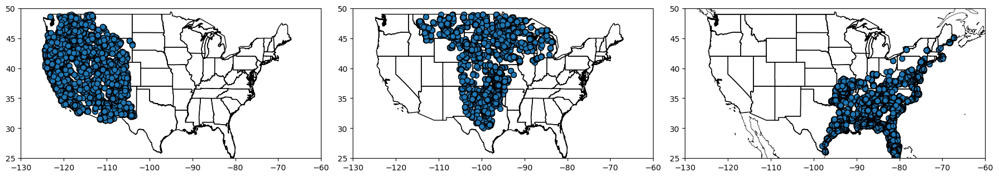

In [295]:
fig, ax = plt.subplots(1,3,figsize=(18,12))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')
# country_eco.plot(column='Biome (Olson)',cmap='tab20',ax=ax[0],edgecolor=None)
# country_eco.plot(column='Biome (Olson)',cmap='tab20',ax=ax[1],edgecolor=None)
# country_eco.plot(column='Biome (Olson)',cmap='tab20',ax=ax[2],edgecolor=None)
ax[0].set_xlim([-130,-60])
ax[1].set_xlim([-130,-60])
ax[2].set_xlim([-130,-60])
ax[0].set_ylim([25,50])
ax[1].set_ylim([25,50])
ax[2].set_ylim([25,50])

country_shp.plot(facecolor='none',edgecolor='black',ax=ax[0])
country_shp.plot(facecolor='none',edgecolor='black',ax=ax[1])
country_shp.plot(facecolor='none',edgecolor='black',ax=ax[2])

ax[0].scatter(W_df['Longitude'],W_df['Latitude'],edgecolor='black',s=50)
ax[1].scatter(GP_df['Longitude'],GP_df['Latitude'],edgecolor='black',s=50)
ax[2].scatter(SATL_df['Longitude'],SATL_df['Latitude'],edgecolor='black',s=50)

plt.tight_layout()

In [348]:
AK_df.groupby(['Burn Objective']).size()

Burn Objective
Hazardous Fuels Reduction    124
Other prescribed burn        175
dtype: int64

In [349]:
124/833

0.148859543817527

In [338]:
np.unique(SATL_df['Year'])

array([1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994,
       1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023])

### Plot burns by ecoregion in each biome

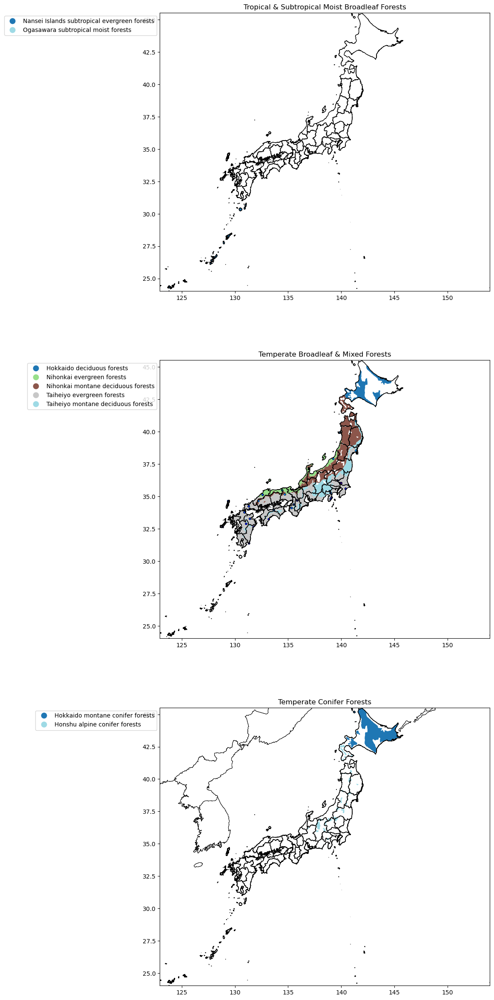

In [7]:
mkrs = ['o','^','s','D','*','p','X','H','.','P','d','v','2','_','|']
htch = ['/','+','.','-','O','x','o','*','|','\|','O.','Ox']
i=0

# biome = 'Tropical & Subtropical Coniferous Forests'
biomes = [biome_dict_inv[i] for i in np.unique(country_eco['BIOME'])]
fig, axs = plt.subplots(len(biomes),1,figsize=(10,30))
axs = axs.ravel()
for biome in biomes:
    ax = axs[i]
    cno = pycno.cno()
    cno.draw('MWDB_Coasts_Countries_1.cnob')
    # country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=ax,edgecolor=None,legend=True,
    #                 legend_kwds={'bbox_to_anchor':(0,0,1,-0.1),'ncol':3})
    country_eco[country_eco['BIOME']==biome_dict[biome]].plot(column='ECO_NAME',cmap='tab20',legend=True,ax=ax,
                 legend_kwds={'bbox_to_anchor':(0,1,0,0),'ncol':1},alpha=1)
    
    biome_idx = country_df['Biome (Olson)']==biome
    biome_lat = country_df[biome_idx]['Latitude']
    biome_lon = country_df[biome_idx]['Longitude']
    biome_DOY = country_df[biome_idx]['DOY']
    
    sc = ax.scatter(biome_lon,biome_lat,c=biome_DOY,s=10,marker='o',edgecolors='black',cmap='jet',
                vmin=0,vmax=365,linewidth=0.5,label=biome,alpha=0.7)
    ax.set_title(biome)
    if country=='USA':
        ax.set_xlim([-127,-65])
        ax.set_ylim([25,50])
    else:
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
    country_shp.plot(facecolor='none',edgecolor='black',ax=ax)
    i+=1

# for biome in biomes:
#     mkr = mkrs[i]
#     biome_idx = country_df['Biome (Olson)']==biome
#     biome_lat = country_df[biome_idx]['Latitude']
#     biome_lon = country_df[biome_idx]['Longitude']

#     # Color code by day of year
#     biome_DOY = country_df[biome_idx]['DOY']

#     #     country_eco.loc[country_eco['BIOME']==biome_dict[biome]].plot(hatch=htch[i],ax=ax,label=biome,
#     #                                                                   facecolor='none',edgecolor='gray')
#     sc = ax.scatter(biome_lon,biome_lat,c=biome_DOY,s=10,marker='o',edgecolors='black',cmap='jet',
#                     vmin=0,vmax=365,linewidth=0.5,label=biome,alpha=0.7)
    # i+=1
# DOY colorbar
# cbar = plt.colorbar(sc,ax=ax,fraction=0.015,pad=0.01)
# cbar.set_ticks(MOY)
# cbar.set_ticklabels(months)

# Color code by land cover type
# country_lc = country_df['Land Cover (Pettinari & Chuvieco)']
# Set1 = cm.get_cmap("Set1").colors[0:len(land_covers)]
# colors = dict(zip(land_covers,Set1))
# colors[np.nan] = (1,1,1)

# Land Cover Scatter
# i=0
# for lc in land_covers:
#     country_lc = country_df[country_df['Land Cover (Pettinari & Chuvieco)']==lc]
#     sc = ax.scatter(country_lc['Longitude'],country_lc['Latitude'],
#                     s=50,marker=mkrs[i],edgecolors='black',linewidth=0.5,label=lc)
#     i+=1
# ax.legend(title='Land Cover Types')

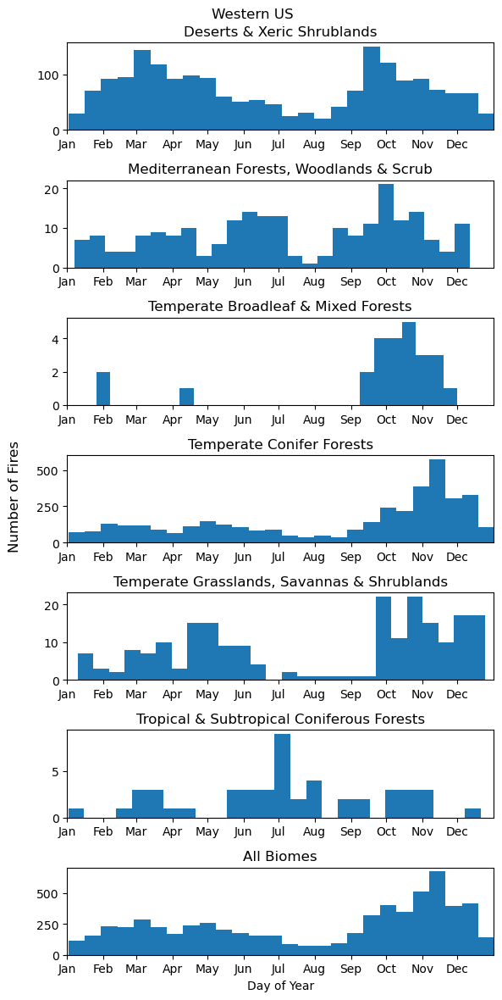

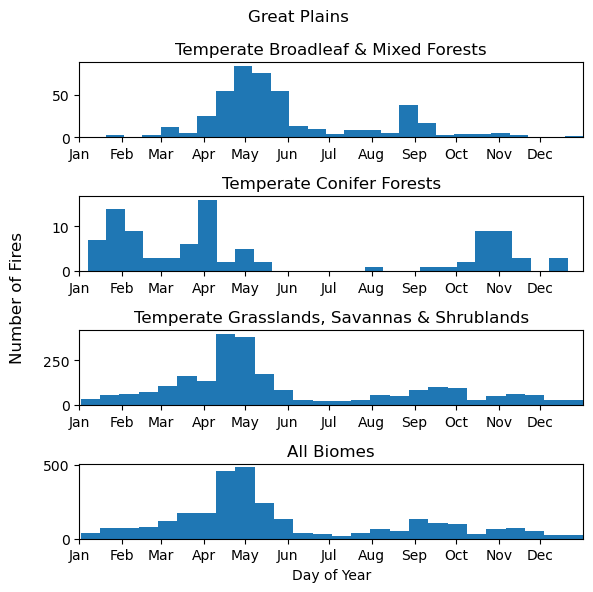

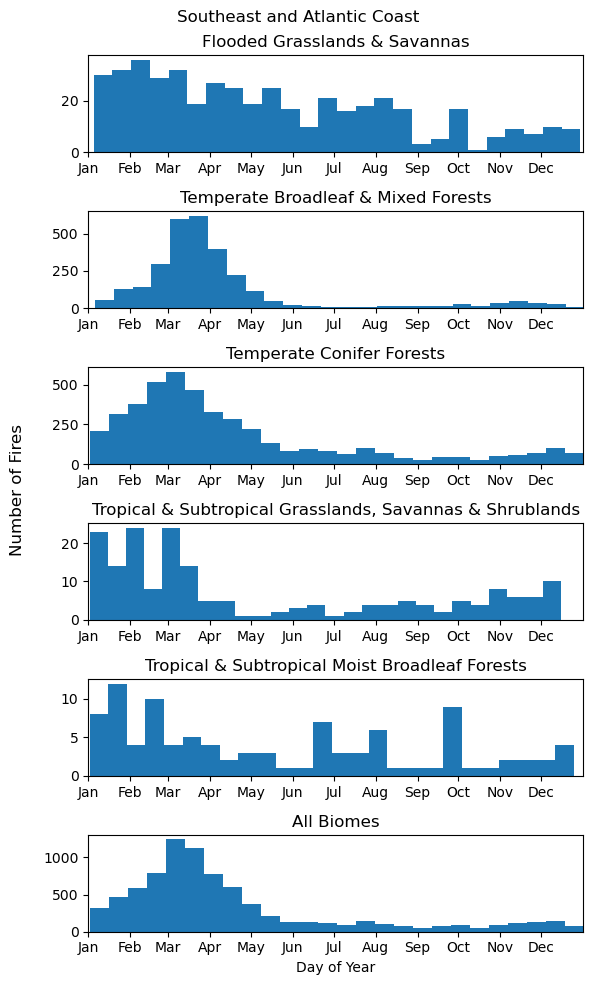

In [123]:
# Fire count by season and biome
MOY = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30])
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
US_df = [W_df,GP_df,SATL_df]
US_reg = ['Western US','Great Plains','Southeast and Atlantic Coast']
US_abbr = ['W','GP','SATL']
j=0
for reg_df in US_df:
    reg_biomes = np.unique(reg_df['Biome (Olson)'].dropna())
    fig,ax = plt.subplots(len(reg_biomes)+1,1,figsize=(6,len(reg_biomes)*2))
    i=0
    for biome in reg_biomes:
        counts = reg_df[reg_df['Biome (Olson)']==biome]['DOY']
        ax[i].hist(counts,bins=26)
        ax[i].set_xlim([1,365])
        ax[i].set_title(biome)
        ax[i].set_xticks(MOY)
        ax[i].set_xticklabels(months)
    #     ax[i].set_yticks([])
        i+=1

    ax[len(reg_biomes)].hist(reg_df['DOY'],bins=26)
    ax[len(reg_biomes)].set_xlim([1,365])
    ax[len(reg_biomes)].set_xticks(MOY)
    ax[len(reg_biomes)].set_xticklabels(months)
    ax[len(reg_biomes)].set_title('All Biomes')
    ax[len(reg_biomes)].set_xlabel('Day of Year')
    fig.supylabel('Number of Fires')
    fig.suptitle(US_reg[j])
    plt.tight_layout()
#     plt.savefig('fire_count_seasonality_by_biome_'+US_abbr[j]+'.png',bbox_inches='tight')
    j+=1

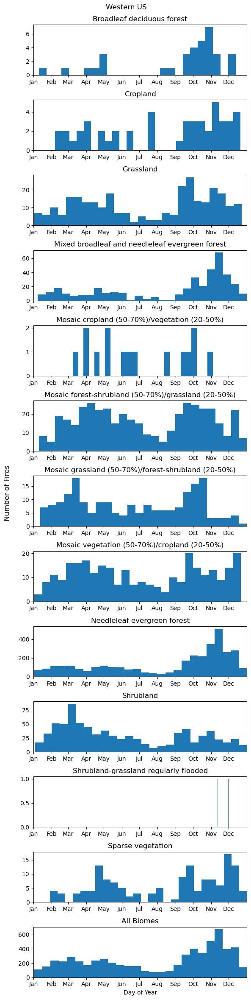

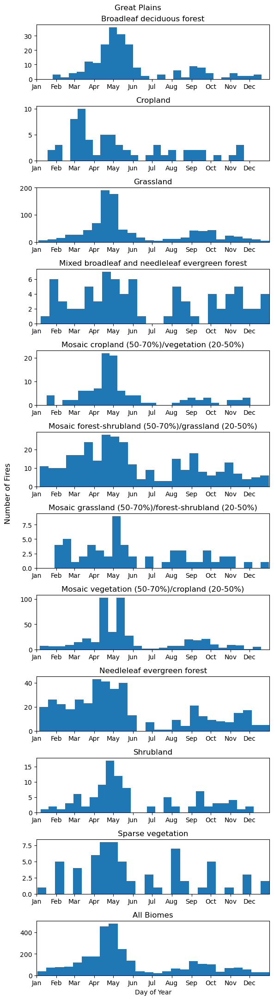

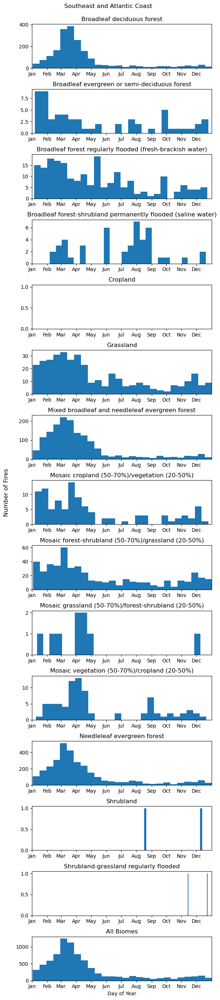

In [53]:
# Fire count by season and biome
MOY = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30])
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
US_df = [W_df,GP_df,SATL_df]
US_reg = ['Western US','Great Plains','Southeast and Atlantic Coast']
US_abbr = ['W','GP','SATL']
j=0
for reg_df in US_df:
    reg_biomes = np.unique(reg_df['Land Cover (Pettinari & Chuvieco)'].dropna())
    fig,ax = plt.subplots(len(reg_biomes)+1,1,figsize=(6,len(reg_biomes)*2))
    i=0
    for biome in reg_biomes:
        counts = reg_df[reg_df['Land Cover (Pettinari & Chuvieco)']==biome]['DOY']
        ax[i].hist(counts,bins=26)
        ax[i].set_xlim([1,365])
        ax[i].set_title(biome)
        ax[i].set_xticks(MOY)
        ax[i].set_xticklabels(months)
    #     ax[i].set_yticks([])
        i+=1

    ax[len(reg_biomes)].hist(reg_df['DOY'],bins=26)
    ax[len(reg_biomes)].set_xlim([1,365])
    ax[len(reg_biomes)].set_xticks(MOY)
    ax[len(reg_biomes)].set_xticklabels(months)
    ax[len(reg_biomes)].set_title('All Biomes')
    ax[len(reg_biomes)].set_xlabel('Day of Year')
    fig.supylabel('Number of Fires')
    fig.suptitle(US_reg[j])
    plt.tight_layout()
    plt.subplots_adjust(top=0.96)
    plt.savefig('fire_count_seasonality_by_lc_'+US_abbr[j]+'.png',bbox_inches='tight')
    j+=1

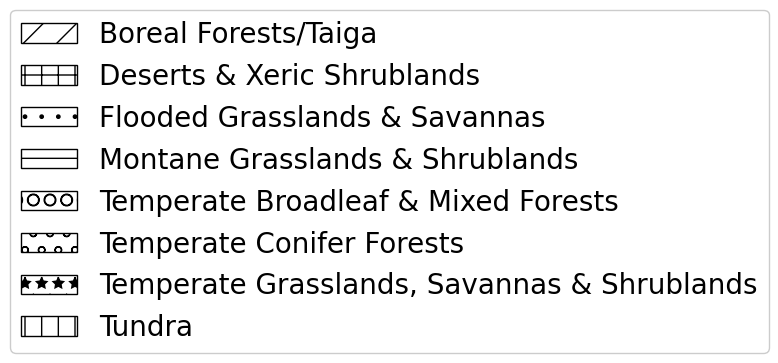

In [17]:
legend_elements = []
i=0
for biome in biomes:
    legend_elements.append(Patch(facecolor='White',edgecolor='Black',hatch=htch[i],label=biomes[i]))
    i+=1
    
fig, ax = plt.subplots(figsize=(1,1))
ax.legend(handles=legend_elements,loc='center',fontsize=20,framealpha=1)

## Global Analysis

### Seasonal Histograms with Biomes

In [5]:
# Set colors for each biome
tab20b = cm.get_cmap("tab20b").colors
tab20c = cm.get_cmap("tab20c").colors
tab20 = cm.get_cmap("tab20").colors
Set2 = cm.get_cmap("Set2").colors
Paired = cm.get_cmap("Paired").colors
biome_colors = {'Boreal Forests/Taiga':tab20[1],'Tundra':tab20c[17],'Deserts & Xeric Shrublands':tab20b[10],
               'Mediterranean Forests, Woodlands & Scrub':tab20b[8],'Montane Grasslands & Shrublands':Set2[5],
               'Flooded Grasslands & Savannas':tab20[5],'Temperate Grasslands, Savannas & Shrublands':Set2[4],
               'Tropical & Subtropical Grasslands, Savannas & Shrublands':tab20[17],
               'Temperate Broadleaf & Mixed Forests':(0.2,0.4,0),
               'Tropical & Subtropical Moist Broadleaf Forests':tab20[4],
               'Tropical & Subtropical Dry Broadleaf Forests':tab20[16],'Temperate Conifer Forests':Paired[11],
                'Tropical & Subtropical Coniferous Forests':tab20b[5]}

In [63]:
fig,ax = plt.subplots(figsize=(16,10))
# country_df[country_df['Biome (Olson)']==biomes[0]]['Area Burned (Ha)']
biome_BA = []
for biome in biomes:
    biome_df = country_df[country_df['Biome (Olson)']==biome]
    BA_monthly = []
    for i in range(0,len(MOY_bins)-1):
        MOY_idx = (biome_df['DOY']>=MOY_bins[i]+1)&(biome_df['DOY']<=MOY_bins[i+1])
        BA_mo = biome_df['Area Burned (Ha)'][MOY_idx].sum()
        BA_monthly.append(BA_mo)
    biome_BA.append(BA_monthly)
    clrs.append(biome_colors[biome])
    ax.bar(months,biome_BA)

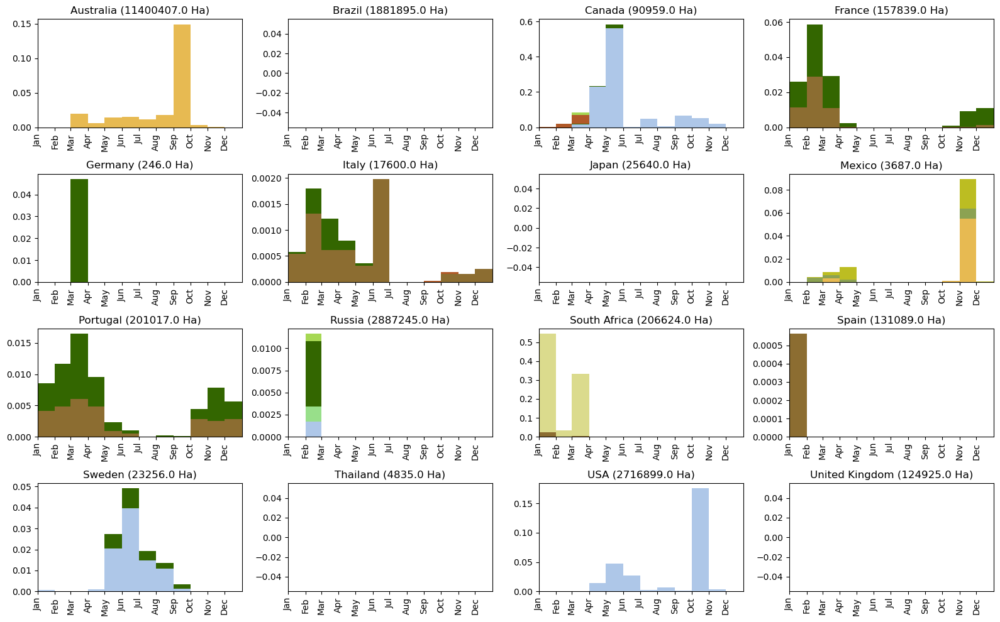

In [7]:
fig,ax = plt.subplots(4,4,figsize=(16,10))
ax = ax.ravel()

i=0
for country in countries:
    country_df = df[df['Country']==country]
    biomes = np.unique(country_df['Biome (Olson)'].dropna())
    biome_counts = []
    biome_BA = []
    clrs = []
    for biome in biomes:
        biome_df = country_df[country_df['Biome (Olson)']==biome]
        BA = biome_df['Area Burned (Ha)']
        counts = biome_df['DOY']
        biome_counts.append(counts)
        biome_BA.append(BA)
        clrs.append(biome_colors[biome])
    # Total number of Rx fires
#     tot = np.sum([len(i) for i in biome_counts])
    tot = np.sum([np.sum(i) for i in biome_counts])
#     wts = [np.ones(np.shape(i))/tot for i in biome_counts]
    # Weigh each fire by its area
    wts = [i/tot for i in biome_BA]
    ax[i].hist(biome_counts,MOY_bins,stacked=True,label=biomes,color=clrs,weights=wts)
    ax[i].set_xlim([1,365])
    ax[i].set_title(country+' ('+str(np.floor(tot))+' Ha)')
    ax[i].set_xticks(MOY)
    ax[i].set_xticklabels(months,rotation=90)
#     ax[i].set_ylim([0,1])
#     ax[i].legend()
    i+=1
plt.tight_layout()

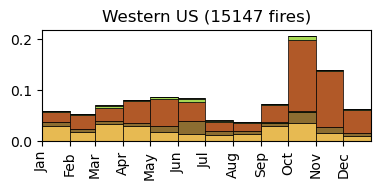

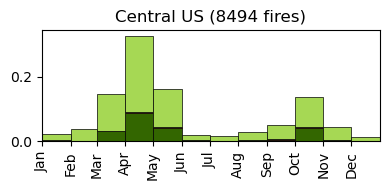

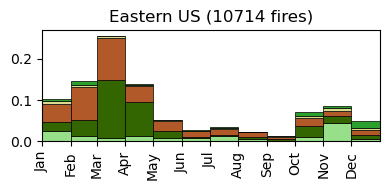

In [2640]:
# fig,ax = plt.subplots(4,4,figsize=(16,10))
# ax = ax.ravel()

# i=0
# for country in countries:
#     fig,ax = plt.subplots(figsize=(4,2))
#     country_df = df[df['Country']==country]
#     biomes = np.unique(country_df['Biome (Olson)'].dropna())
#     biome_counts = []
#     clrs = []
#     for biome in biomes:
#         counts = country_df[country_df['Biome (Olson)']==biome]['DOY']
#         biome_counts.append(counts)
#         clrs.append(biome_colors[biome])
#     tot = np.sum([len(i) for i in biome_counts])
#     wts = [np.ones(np.shape(i))/tot for i in biome_counts]
#     ax.hist(biome_counts,MOY_bins,stacked=True,label=biomes,color=clrs,weights=wts,edgecolor='black',linewidth=0.5)
#     ax.set_xlim([1,365])
#     ax.set_title(country+' ('+str(tot)+' fires)')
#     ax.set_xticks(MOY)
#     ax.set_xticklabels(months,rotation=90)
# #     ax[i].set_ylim([0,1])
# #     ax[i].legend()
#     i+=1
#     plt.tight_layout()
# #     plt.savefig(country+'_hist.png',bbox_inches='tight',transparent=True)

i=0
US_names = ['Western US','Central US','Eastern US']
for reg_df in [W_df,GP_df,SATL_df]:
    fig,ax = plt.subplots(figsize=(4,2))
    biomes = np.unique(reg_df['Biome (Olson)'].dropna())
    biome_counts = []
    clrs = []
    for biome in biomes:
        counts = reg_df[reg_df['Biome (Olson)']==biome]['DOY']
        biome_counts.append(counts)
        clrs.append(biome_colors[biome])
    tot = np.sum([len(i) for i in biome_counts])
    wts = [np.ones(np.shape(i))/tot for i in biome_counts]
    ax.hist(biome_counts,MOY_bins,stacked=True,label=biomes,color=clrs,weights=wts,edgecolor='black',linewidth=0.5)
    ax.set_xlim([1,365])
    ax.set_title(US_names[i]+' ('+str(tot)+' fires)')
    ax.set_xticks(MOY)
    ax.set_xticklabels(months,rotation=90)
    plt.tight_layout()
    plt.savefig('Figures/'+US_names[i]+'_hist.png',bbox_inches='tight',transparent=True)
    i+=1

### Land cover histograms for each country

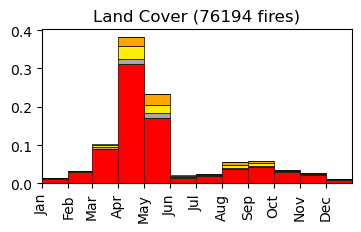

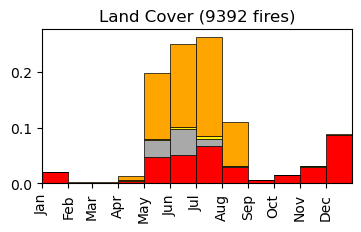

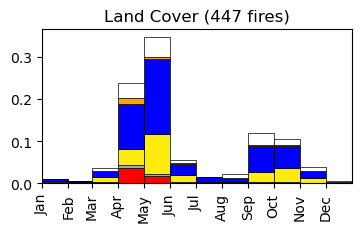

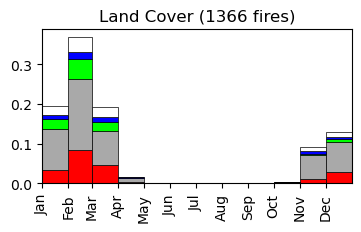

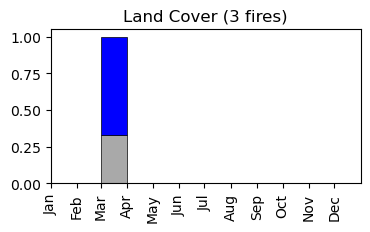

...

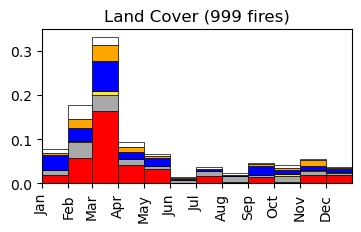

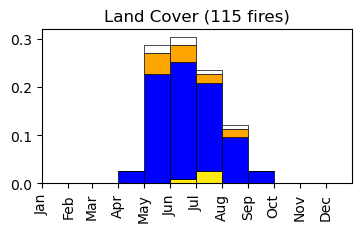

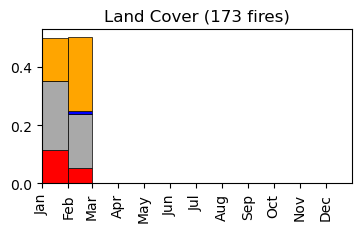

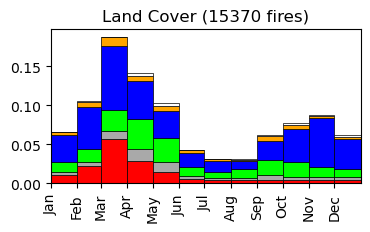

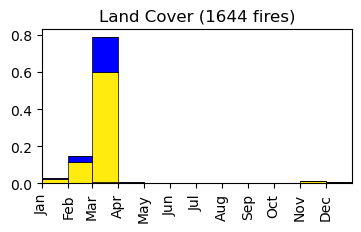

In [108]:
j=0
for country in countries:
    country_df = df[df['Country']==country]
#     land_covers = [i for i in lc_dict.keys() if i in np.unique(country_df['Land Cover (Pettinari & Chuvieco)'].dropna().values)]
    lc_classes = np.unique(country_df['lc_class'].dropna())
    lc_counts = []
    clrs = []
    hatches = []
    legend_elements = []
    i=0
    fig, ax = plt.subplots(figsize=(4,2))
    for lc_class in lc_classes:
#     for lc in land_covers:
        counts = country_df[country_df['lc_class']==lc_class]['DOY']
        # Use color of first land cover within land cover class
        lc = country_df[country_df['lc_class']==lc_class]['Land Cover (Pettinari & Chuvieco)'].iloc[0]
        lc_counts.append(counts)
        clr = lc_dict[lc]['clr']
#         htch = lc_dict[lc]['htch']
        clrs.append(clr)
#         htchs.append(htch)
        legend_elements.append(Patch(facecolor=clr,edgecolor='Black',label=lc_class))
        i+=1

    tot = np.sum([len(j) for j in lc_counts])
    wts = [np.ones(np.shape(j))/tot for j in lc_counts]
    ax.hist(lc_counts,MOY_bins,stacked=True,color=clrs,weights=wts,
                                edgecolor='black',linewidth=0.5)
    ax.set_xlim([1,365])
    ax.set_title('Land Cover ('+str(tot)+' fires)')
    ax.set_xticks(MOY)
    ax.set_xticklabels(months,rotation=90)

#     if len(land_covers)<3:
#         n = 1
#     else:
#         n = 3
# #     n=1
#     box = ax.get_position()
#     ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
#     ax.legend(handles=legend_elements,loc='center left',bbox_to_anchor=(1, 0.5),
#               fontsize=10,framealpha=0,ncol=1,facecolor=(1,1,1,1))
#     plt.tight_layout()
    plt.savefig('GlobalRx_'+country+'_landcover.png',bbox_inches='tight')

In [366]:
US_df['DOY']=pd.DatetimeIndex(US_df['Date']).dayofyear

### Make biome histogram + legends for each country

In [6]:
PR_df = US_df.loc[US_df['State/Province']=='Puerto Rico']

/tmp/ipykernel_43585/2429768029.py:30: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(figsize=(4,2))


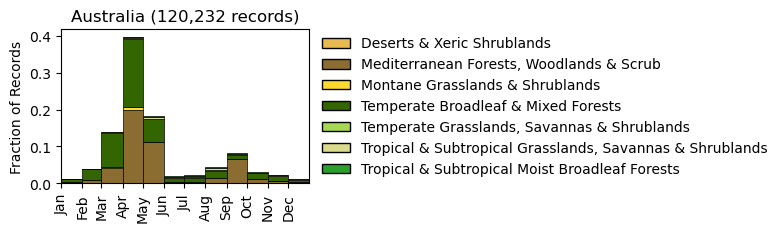

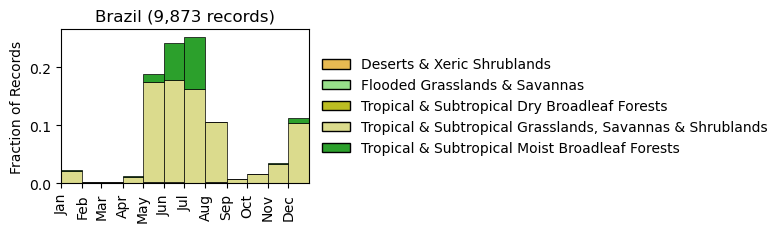

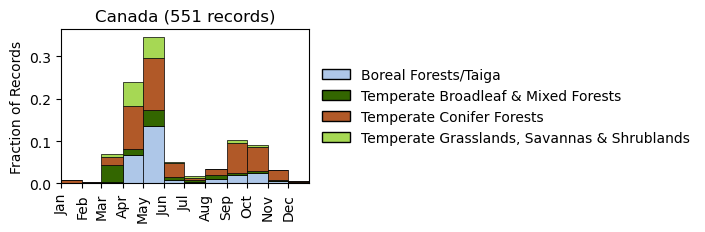

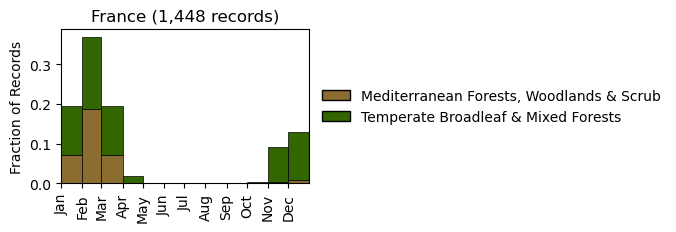

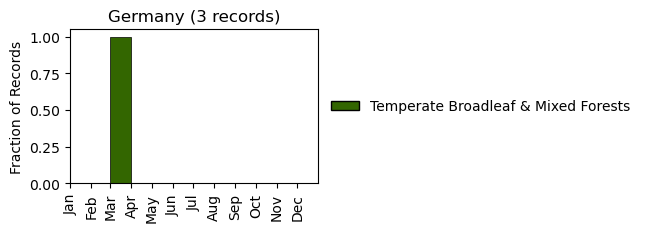

...

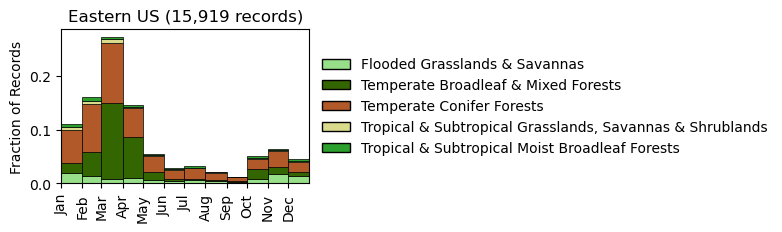

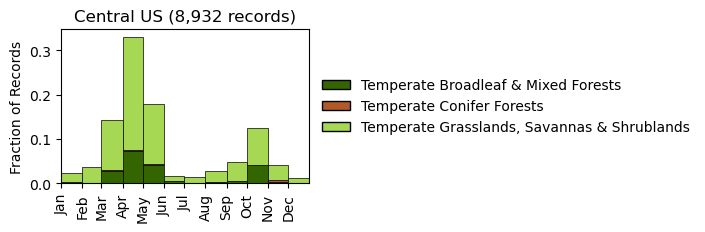

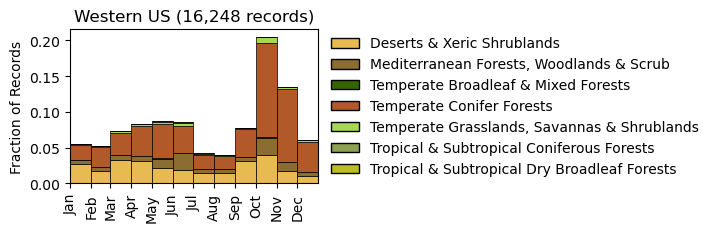

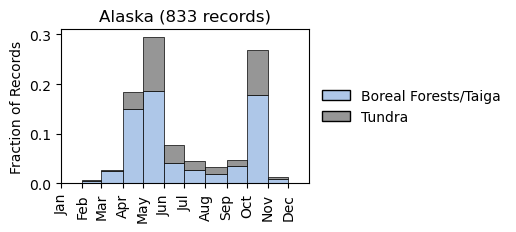

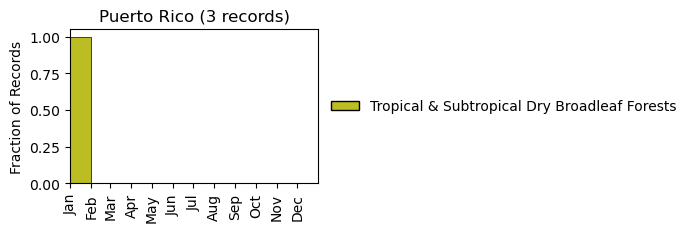

In [13]:
MOY_bins = np.cumsum([0,31,28,31,30,31,30,31,31,30,31,30,31])
MOY = MOY_bins[:-1]
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

j=0
countries = np.unique(df['Country'].dropna())
for country in countries:
    country_df = df[df['Country']==country]
    
    if country=='United States':
        country_dfs = [country_df,SATL_df,GP_df,W_df,AK_df,PR_df]
        titles = ['United States','Eastern US','Central US','Western US','Alaska','Puerto Rico']
    else:
        country_dfs = [country_df]
    i=0
    for country_df in country_dfs:
        biomes = np.unique(country_df['Biome (Olson)'].dropna())
        biome_counts = []
        clrs = []
        legend_elements = []
        biome_labels = []
        for biome in biomes:
            country_df = country_df[country_df['Biome (Olson)']!='Lake']
            counts = country_df[country_df['Biome (Olson)']==biome]['DOY']
            biome_counts.append(counts)
            clrs.append(biome_colors[biome])
            if len(counts)>0.1 and biome != 'Lake':
                legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome))

        fig, ax = plt.subplots(figsize=(4,2))
        tot = np.sum([len(j) for j in biome_counts])
        wts = [np.ones(np.shape(j))/tot for j in biome_counts]
        ax.hist(biome_counts,MOY_bins,stacked=True,label=biomes,color=clrs,weights=wts,
                edgecolor='black',linewidth=0.5)
        ax.set_xlim([1,365])
        if country == 'United States':
            ax.set_title(titles[i]+' ('+"{:,}".format(tot)+' records)')
        else:
            ax.set_title(country+' ('+"{:,}".format(tot)+' records)')
        ax.set_xticks(MOY)
        ax.set_xticklabels(months,rotation=90)
        ax.set_ylabel('Fraction of Records',fontsize=10)
        
        if (len(legend_elements)>7 and len(legend_elements)<9):
            n = 2
            fs = 9
        if len(legend_elements)>8:
            fs = 8
        else:
            n = 1
            fs = 10
        box = ax.get_position()
        ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
        ax.legend(handles=legend_elements,loc='center left',bbox_to_anchor=(1, 0.5),
                  fontsize=fs,framealpha=0,ncol=1,facecolor=(1,1,1,1))
    #     ax.set_position([box.x0, box.y0 + box.height * 0.1,
    #                  box.width, box.height * 0.9])
    #     ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05),ncol=3,framealpha=0)
    #     ax.legend(handles=legend_elements,loc='lower center',bbox_to_anchor=[0.5,-0.5],
    #               fontsize=10,framealpha=0,ncol=n,facecolor=(1,1,1,1))
    #     plt.tight_layout()
        if country == 'United States':
            plt.savefig('Figures/GlobalRx_'+titles[i]+'_hist_biomes_hi_res.png',bbox_inches='tight',dpi=1000)
        else:
            plt.savefig('Figures/GlobalRx_'+country+'_hist_biomes_hi_res.png',bbox_inches='tight',dpi=1000)
        i+=1

### Biome legend for each country

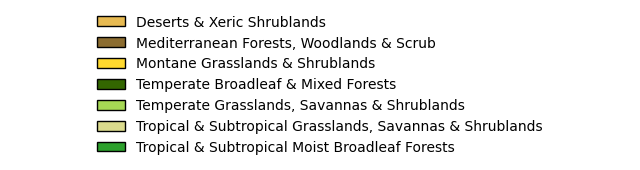

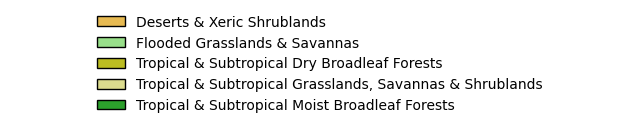

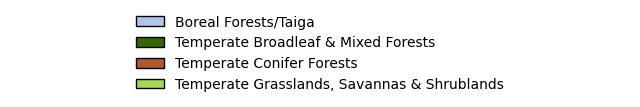

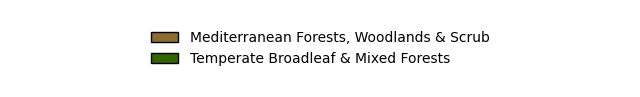

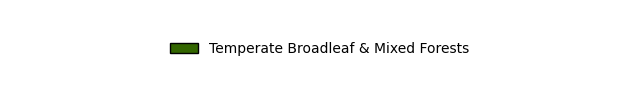

...

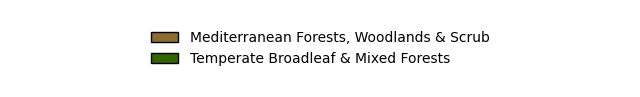

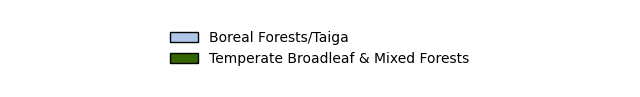

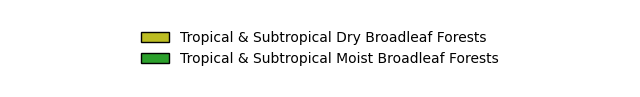

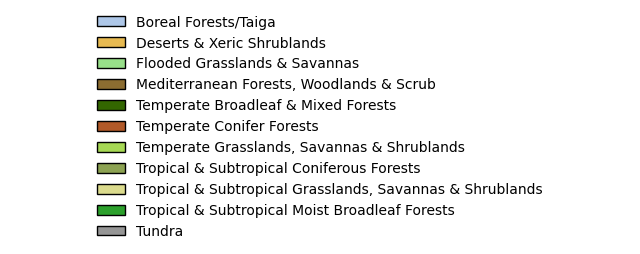

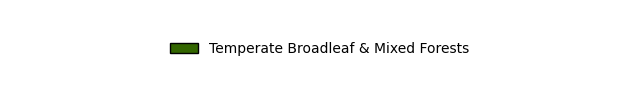

In [16]:
for country in countries:
    country_df = df[df['Country']==country]
    
    fig, ax = plt.subplots(figsize=(8,1))
    
    biomes = np.unique(country_df['Biome (Olson)'].dropna())
    clrs = []
    legend_elements = []
    for biome in biomes:
        counts = country_df[country_df['Biome (Olson)']==biome]['DOY']
        clrs.append(biome_colors[biome])
        if biome != 'Lake':
            legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome))
        
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.get_xaxis().set_ticks([])
    ax.get_yaxis().set_ticks([])
    
    if len(biomes)==1:
        n=1
    elif len(biomes)>2 or len(biomes)<=4:
        n=2
    elif len(biomes)>=5:
        n=3
    ax.legend(handles=legend_elements,loc='center',bbox_to_anchor=[0.5,0.5],
              fontsize=10,framealpha=0,ncol=1,facecolor=(1,1,1,1))
#     plt.savefig(country+'_biome_legend.png',bbox_inches='tight')

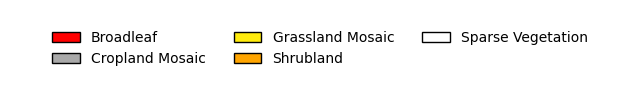

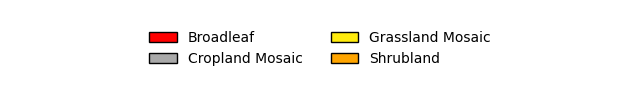

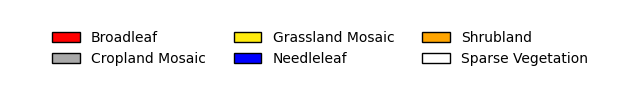

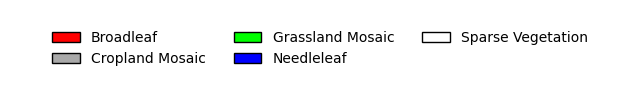

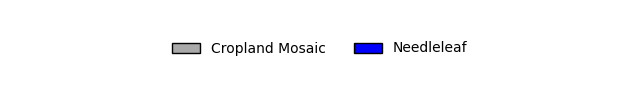

...

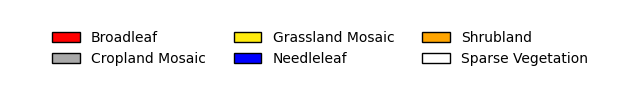

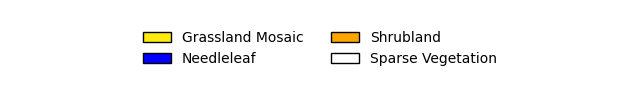

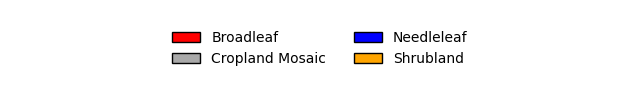

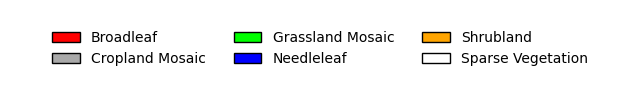

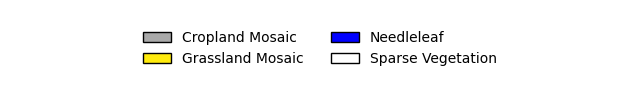

In [125]:
for country in countries:
    country_df = df[df['Country']==country]
#     land_covers = [i for i in lc_dict.keys() if i in np.unique(country_df['Land Cover (Pettinari & Chuvieco)'].dropna().values)]
    lc_classes = np.unique(country_df['lc_class'].dropna())
    clrs = []
    legend_elements = []
    i=0
    fig, ax = plt.subplots(figsize=(8,1))
    for lc_class in lc_classes:
        # Use color of first land cover within land cover class
        lc = country_df[country_df['lc_class']==lc_class]['Land Cover (Pettinari & Chuvieco)'].iloc[0]
        clr = lc_dict[lc]['clr']
        clrs.append(clr)
        legend_elements.append(Patch(facecolor=clr,edgecolor='Black',label=lc_class))
        i+=1
        
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.get_xaxis().set_ticks([])
    ax.get_yaxis().set_ticks([])
    
    if len(lc_classes)<=4:
        n=2
    elif len(lc_classes)>=5:
        n=3
        
    ax.legend(handles=legend_elements,loc='center',bbox_to_anchor=[0.5,0.5],
              fontsize=10,framealpha=0,ncol=n,facecolor=(1,1,1,1))
    plt.savefig(country+'_lc_leg.png',bbox_inches='tight')

### Simplified land cover scatter map for each country

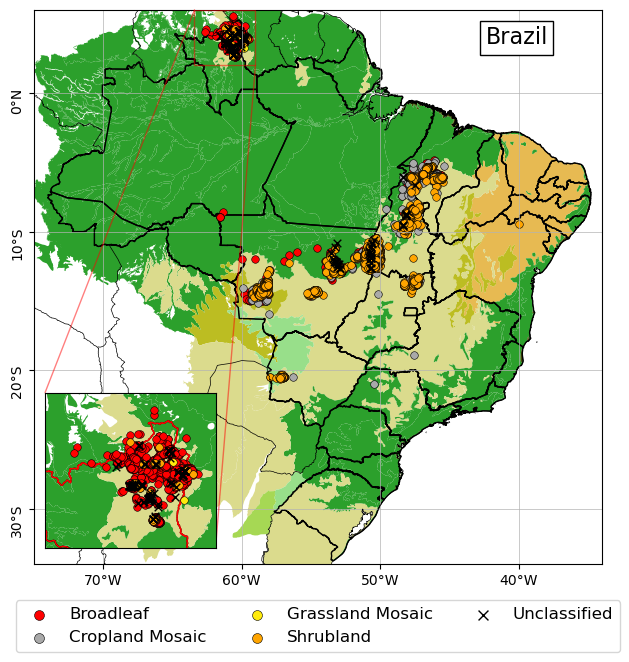

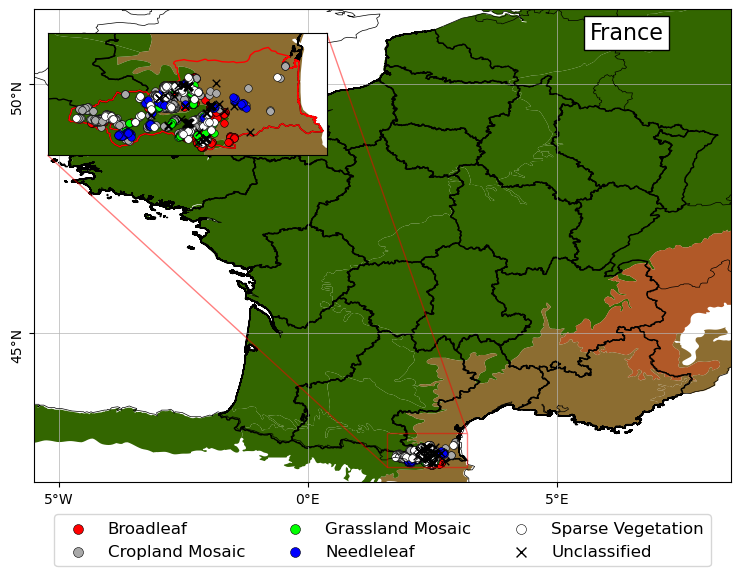

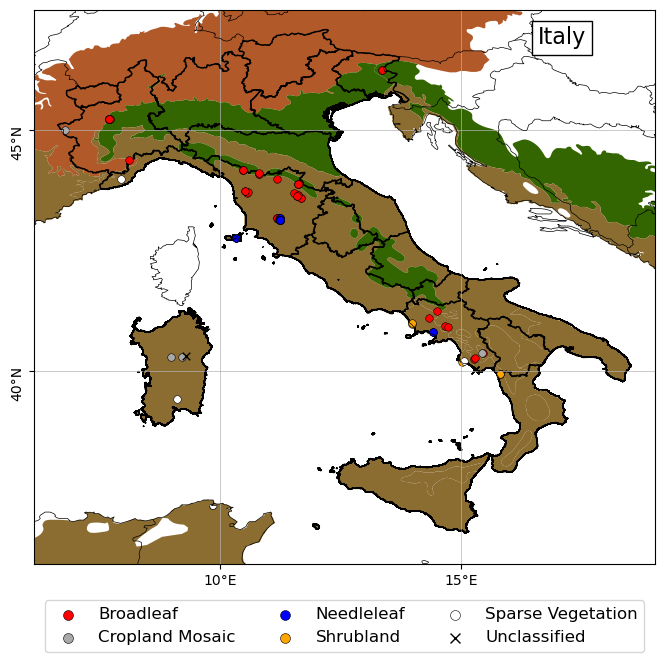

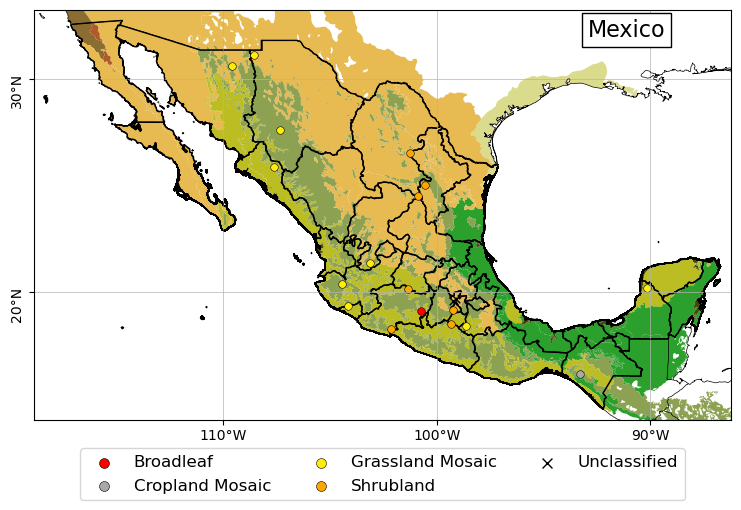

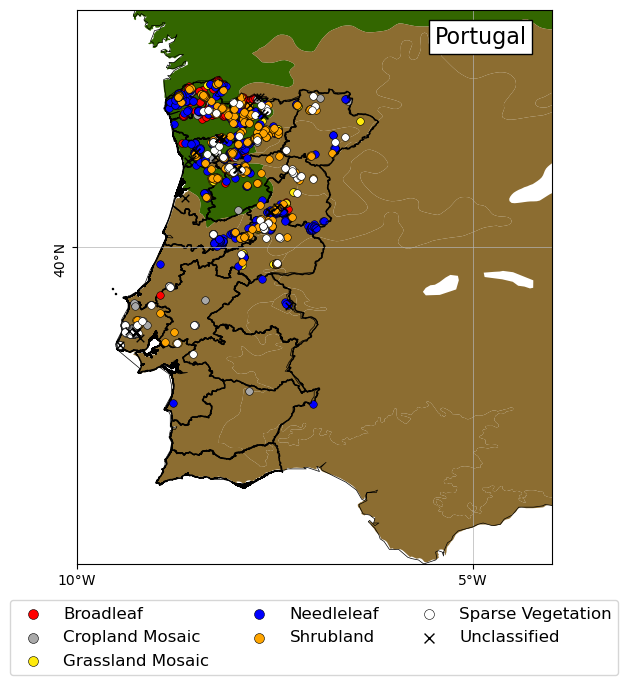

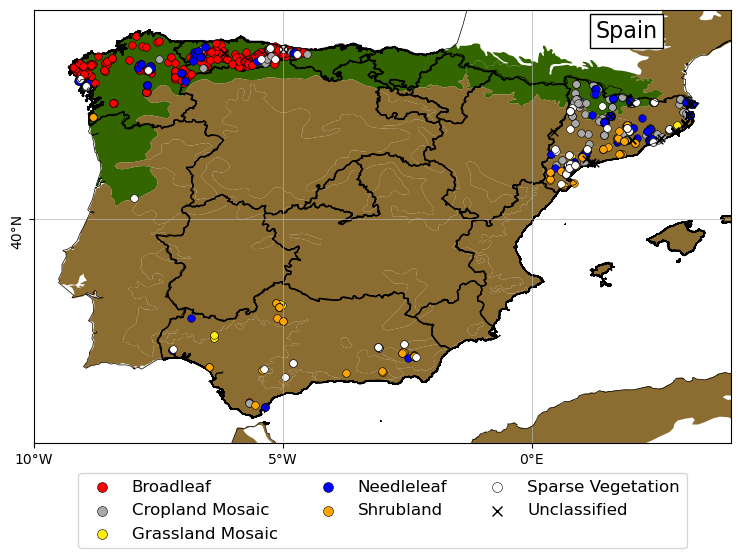

In [128]:
for country in ['Brazil','France','Italy','Mexico','Portugal','Spain']:
    ################################
    
    # Country shapefile
    try:
        country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
    except:
        # If shapefile doesn't have a pre-existing CRS
        country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')
    country_shp.set_index(country_shp.columns[0],inplace=True)
    bounds = country_shp['geometry'].bounds
    
    xlim = [bounds['minx'].min()-0.5,bounds['maxx'].max()+0.5]
    ylim = [bounds['miny'].min()-0.5,bounds['maxy'].max()+0.5]
    
    if country == 'USA':
        xlim = [-125,-67]
        ylim = [25,50]
    elif country == 'Portugal':
        xlim = [-10,-4]
        ylim = [36,43]
    elif country == 'Spain':
        xlim = [-10,4]
        ylim = [35.5,44.2]
    elif country == 'Brazil':
        xlim = [-75,-34]
        ylim = [-34,6]
    elif country == 'Italy':
        ylim = [36,47.5]
    elif country =='France':
        xlim = [-5.5,8.5]
        ylim = [42,51.5]

    # Ecoregions shapefile
    eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
    eco_shp.set_index('OBJECTID',inplace=True)

    # Find ecoregions only within country
    country_eco_shp = gpd.sjoin(country_shp,eco_shp)

    # Index of ecoregions in country in original ecoregion shapefile
    eco_idx = np.unique(country_eco_shp['index_right'])

    # Extract ecoregions only within country
    country_eco = eco_shp.loc[eco_idx]

    # Add biome column to ecoregion geodataframe
    i=0
    country_eco['Biome (Olson)'] = ''
    for val in biome_dict.values():
        country_eco.loc[country_eco['BIOME']==val,'Biome (Olson)'] = list(biome_dict.keys())[i]
        i+=1
    
    ################################
    country_df = df[df['Country']==country]

    fig, ax = plt.subplots(figsize=(10,8))
    cno = pycno.cno()
    cno.draw('MWDB_Coasts_Countries_1.cnob')
    
    biomes = np.unique(country_df['Biome (Olson)'])
    country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=ax,categories=biomes,aspect='equal')
    
    deg = u'\N{DEGREE SIGN}'
    if country == 'Spain' or country == 'Portugal' or country == 'France' or country == 'Italy':
        xtx = range(-180,180,5)
        ytx = range(-90,90,5)
        xlab = [str(-i)+deg+'W' if i<0 else str(i)+deg+'E' for i in xtx]
        ylab = [str(-i)+deg+'S' if i<0 else str(i)+deg+'N' for i in ytx]
    else:
        xtx = range(-180,180,10)
        ytx = range(-90,90,10)
        xlab = [str(-i)+deg+'W' if i<0 else str(i)+deg+'E' for i in xtx]
        ylab = [str(-i)+deg+'S' if i<0 else str(i)+deg+'N' for i in ytx]
    ax.set_xticks(xtx,labels=xlab,rotation=0)
    ax.set_yticks(ytx,labels=ylab,rotation=90)
    ax.grid(visible=True,which='major',axis='both',linewidth=0.5,color=[0.7,0.7,0.7])
    
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    country_shp.plot(facecolor='none',edgecolor='black',ax=ax,aspect='equal')

    for lc_class in np.unique(country_df['lc_class'].dropna()):
        idx = country_df['lc_class']==lc_class
    #     mkr = lc_dict[lc]['mkr']
        lc = country_df['Land Cover (Pettinari & Chuvieco)'][idx].iloc[0]
        clr = lc_dict[lc]['clr']

        ax.scatter(country_df[idx]['Longitude'],country_df[idx]['Latitude'],marker='o',color=clr,
                   edgecolor='black',linewidth=0.4,s=30,label=lc_class)
        
    df_nan = country_df[country_df['lc_class'].isna()]
    if not df_nan.empty:
        ax.scatter(df_nan['Longitude'],df_nan['Latitude'],marker='x',color='black',
                       linewidth=1,s=30,label='Unclassified')
        
###################################### Inset Axes ######################################
    if country == 'France':
        in_ax = ax.inset_axes([0.02,0.62,0.4,0.4],transform=ax.transAxes)
        
        country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=in_ax,categories=biomes,aspect='equal')
        country_shp.plot(facecolor='none',edgecolor='black',ax=in_ax,aspect='equal')
        adm_shp = gpd.read_file(glob.glob(country+'_shp/FRA_adm2/*.shp')[0]).to_crs('EPSG:4326')
        adm_shp[adm_shp['NAME_2']=='Pyrénées-Orientales'].plot(facecolor='none',edgecolor='red',ax=in_ax,aspect='equal')
        
        for lc_class in np.unique(country_df['lc_class'].dropna()):
            idx = country_df['lc_class']==lc_class
            lc = country_df['Land Cover (Pettinari & Chuvieco)'][idx].iloc[0]
            clr = lc_dict[lc]['clr']
            in_ax.scatter(country_df[idx]['Longitude'],country_df[idx]['Latitude'],marker='o',color=clr,
                       edgecolor='black',linewidth=0.4,s=30,label=lc_class)
        df_nan = country_df[country_df['lc_class'].isna()]
        if not df_nan.empty:
            in_ax.scatter(df_nan['Longitude'],df_nan['Latitude'],marker='x',color='black',
                           linewidth=1,s=30,label='Unclassified')
        
        in_ax.set_xticks(xtx,labels=xlab,rotation=0)
        in_ax.set_yticks(ytx,labels=ylab,rotation=90)
        in_ax.grid(visible=True,which='major',axis='both',linewidth=0.5,color=[0.7,0.7,0.7])
        in_ax.set_xlim([1.6,3.2])
        in_ax.set_ylim([42.3,43])
        ax.indicate_inset_zoom(in_ax,edgecolor='red')
        
    if country == 'Brazil':
        in_ax = ax.inset_axes([0.02,0.02,0.3,0.3],transform=ax.transAxes)
        
        country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=in_ax,categories=biomes,aspect='equal')
        country_shp.plot(facecolor='none',edgecolor='black',ax=in_ax,aspect='equal')
        country_shp[country_shp['ADM1_PT']=='Roraima'].plot(facecolor='none',edgecolor='red',ax=in_ax,aspect='equal')
        
        for lc_class in np.unique(country_df['lc_class'].dropna()):
            idx = country_df['lc_class']==lc_class
            lc = country_df['Land Cover (Pettinari & Chuvieco)'][idx].iloc[0]
            clr = lc_dict[lc]['clr']
            in_ax.scatter(country_df[idx]['Longitude'],country_df[idx]['Latitude'],marker='o',color=clr,
                       edgecolor='black',linewidth=0.4,s=30,label=lc_class)
        df_nan = country_df[country_df['lc_class'].isna()]
        if not df_nan.empty:
            in_ax.scatter(df_nan['Longitude'],df_nan['Latitude'],marker='x',color='black',
                           linewidth=1,s=30,label='Unclassified')
        
        in_ax.set_xticks([])
        in_ax.set_yticks([])
        in_ax.grid(visible=True,which='major',axis='both',linewidth=0.5,color=[0.7,0.7,0.7])
        in_ax.set_xlim([-63.4,-59])
        in_ax.set_ylim([2,6])
        ax.indicate_inset_zoom(in_ax,edgecolor='red')
        
################################## Legend and Text Box ##################################        
#     clrs = []
#     legend_elements = []
#     for biome in np.unique(country_df['Biome (Olson)'].dropna()):
#         clrs.append(biome_colors[biome])
#         legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome))
    
    box = ax.get_position()
    ax.set_position([box.x0, box.y0 + box.height * 0.1,
                     box.width, box.height * 0.9])
    ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.05),
              fancybox=True,ncol=3,fontsize=12,markerscale=1.3)
    ax.text(0.85,0.95,country,horizontalalignment='center',verticalalignment='center',
            transform=ax.transAxes,bbox=dict(facecolor='white'),fontsize=16)
#     ax.set_title(country,fontsize=32)
    plt.savefig('Figures/'+country+'_map_scatter_lc_leg.png',bbox_inches='tight',transparent=True)

### FWI Distributions

#### Fit the FWI distribution
* Do not need to run if file exists

In [15]:
for country in countries:
    country_df = df[df['Country']==country]
    biomes = np.unique(country_df['Biome (Olson)'].dropna())
    dist = pd.DataFrame(index=biomes,columns=FWIs)
    if glob.glob('FWI_dist/'+country+'.pkl'):
        continue
    for biome in biomes:
        biome_df = country_df[country_df['Biome (Olson)']==biome]
        if len(biome_df) < 20: # If less than 20 data points, do not fit distribution
            continue
        for FWI in FWIs:
            X = np.sort(biome_df[FWI].dropna().values)
            try:
                kde = neighbors.KernelDensity(kernel='gaussian').fit(X.reshape(-1,1))
                Y = np.exp(kde.score_samples(X.reshape(-1,1)))
                dist[FWI].loc[biome] = Y
            except:
                continue
    Path('FWI_dist').mkdir(parents=True,exist_ok=True)
    with open('FWI_dist/'+country+'.pkl','wb') as handle:
            pickle.dump(dist,handle,protocol=pickle.HIGHEST_PROTOCOL)
    print(country)

#### Plot FWI distributions for each biome in each country

In [13]:
title_dict = {'Boreal Forests/Taiga':'Boreal Forests/Taiga',
              'Deserts & Xeric Shrublands':'Deserts & Xeric \nShrublands',
       'Flooded Grasslands & Savannas':'Flooded Grasslands \n& Savannas',
       'Mediterranean Forests, Woodlands & Scrub':'Mediterranean Forests, \nWoodlands & Scrub',
       'Montane Grasslands & Shrublands':'Montane Grasslands \n& Shrublands',
       'Temperate Broadleaf & Mixed Forests':'Temperate Broadleaf\n& Mixed Forests',
       'Temperate Conifer Forests':'Temperate Conifer\nForests',
       'Temperate Grasslands, Savannas & Shrublands':'Temperate Grasslands,\nSavannas & Shrublands',
       'Tropical & Subtropical Coniferous Forests':'Tropical & Subtropical\nConiferous Forests',
       'Tropical & Subtropical Dry Broadleaf Forests':'Tropical & Subtropical\nDry Broadleaf Forests',
       'Tropical & Subtropical Grasslands, Savannas & Shrublands':'Tropical & Subtropical\nGrasslands, Savannas\n& Shrublands',
       'Tropical & Subtropical Moist Broadleaf Forests':'Tropical & Subtropical\nMoist Broadleaf Forests',
       'Tundra':'Tundra'}

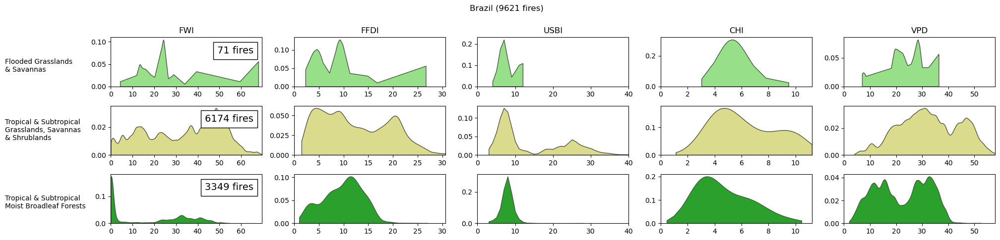

In [24]:
for country in ['Brazil']:
    with open('FWI_dist/'+country+'.pkl','rb') as handle:
        FWI_dist = pickle.load(handle)
    FWI_dist.dropna(inplace=True)
    if len(FWI_dist)<1:
        continue
    country_df = df[df['Country']==country]
    biomes = FWI_dist.index
#     if len(biomes)<=1:
    l = 1.6*len(biomes)
#     else:
#         l = len(biomes)
    fig,ax = plt.subplots(len(biomes),5,figsize=(20,l))
    if len(biomes)<=1:
        ax = ax.reshape(1,5)
    i=0
    for biome in biomes:
        j=0
        biome_df = country_df[country_df['Biome (Olson)']==biome]
        for FWI in FWIs:
            X = np.sort(biome_df[FWI].dropna().values)
            Y = FWI_dist[FWI].loc[biome]
#             try:
            ax[i][j].fill_between(X,np.zeros(np.shape(Y)),Y,facecolor=biome_colors[biome],edgecolor=[0.3,0.3,0.3])
#             except:
#                 continue
            ax[i][j].set_xlim([0,country_df[FWI].max()])
            ax[i][j].set_ylim(bottom=0)
            if i==0:
                ax[0][j].set_title(FWI.replace(' Value (ERA5)',''))
#             if i<len(biomes)-1:
#                 ax[i][j].set_xticks([])
            j+=1
        ax[i][0].annotate(title_dict[biome],xy=(-0.7,0.3),xycoords='axes fraction',fontsize=10,rotation=0)
        label = AnchoredText(str(len(X))+' fires',prop=dict(size=14),frameon=True,loc='upper right')
        label.patch.set_boxstyle("round,pad=0.,rounding_size=0")
        ax[i][0].add_artist(label)
        i+=1
    fig.suptitle(country+' ('+str(len(country_df))+' fires)',y=1)
    plt.tight_layout()
#     plt.savefig('burn_windows'+country+'.png',bbox_inches='tight')

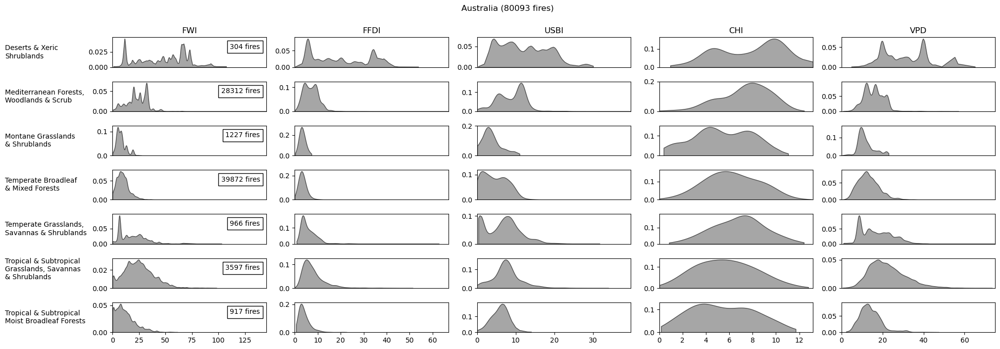

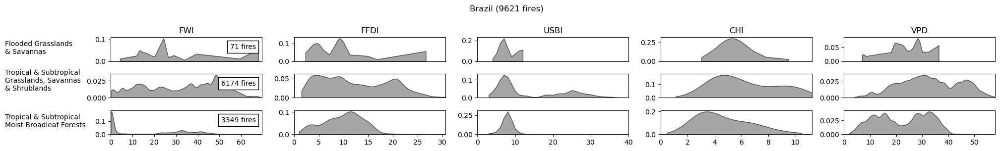

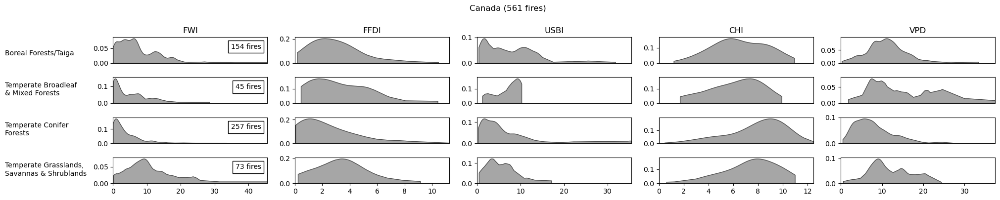

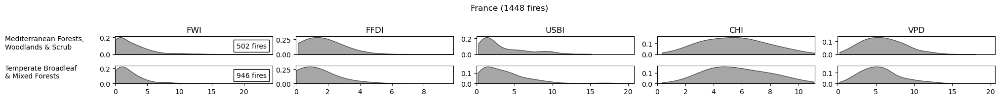

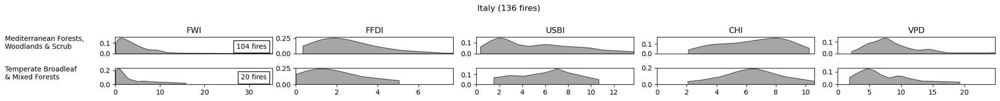

...

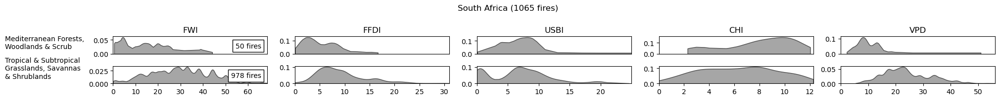

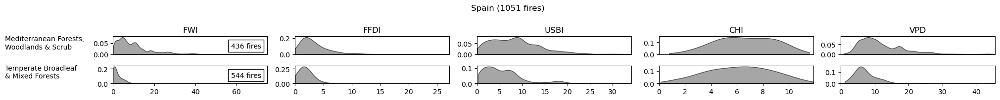

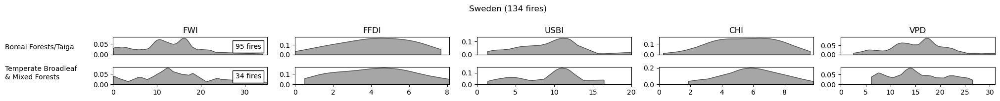

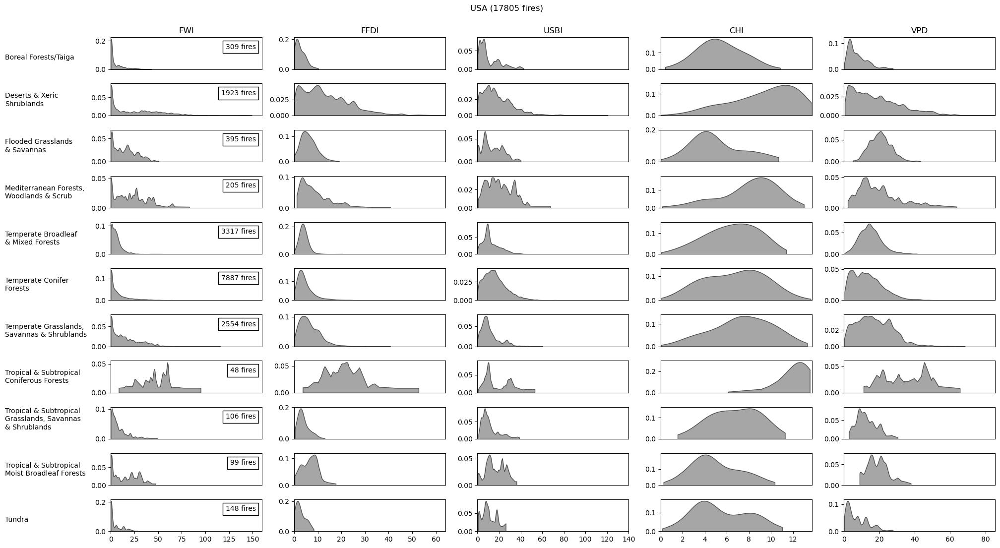

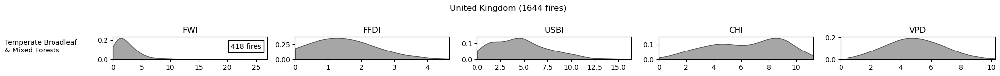

In [53]:
for country in countries:
    with open('FWI_dist/'+country+'.pkl','rb') as handle:
        FWI_dist = pickle.load(handle)
    FWI_dist.dropna(inplace=True)
    if len(FWI_dist)<1:
        continue
    country_df = df[df['Country']==country]
    biomes = FWI_dist.index
    if len(biomes)<=1:
        l = 1.5*len(biomes)
    else:
        l = len(biomes)
    fig,ax = plt.subplots(len(biomes),5,figsize=(20,l))
    if len(biomes)<=1:
        ax = ax.reshape(1,5)
    i=0
    for biome in biomes:
        j=0
        biome_df = country_df[country_df['Biome (Olson)']==biome]
        for FWI in FWIs:
            X = np.sort(biome_df[FWI].dropna().values)
            Y = FWI_dist[FWI].loc[biome]
#             try:
            ax[i][j].fill_between(X,np.zeros(np.shape(Y)),Y,facecolor=[0.5,0.5,0.5,0.7],edgecolor=[0.3,0.3,0.3])
#             except:
#                 continue
            ax[i][j].set_xlim([0,country_df[FWI].max()])
            ax[i][j].set_ylim(bottom=0)
            if i==0:
                ax[0][j].set_title(FWI.replace(' Value (ERA5)',''))
            if i<len(biomes)-1:
                ax[i][j].set_xticks([])
            j+=1
        ax[i][0].annotate(title_dict[biome],xy=(-0.7,0.3),xycoords='axes fraction',fontsize=10,rotation=0)
        label = AnchoredText(str(len(X))+' fires',prop=dict(size=10),frameon=True,loc='upper right')
        label.patch.set_boxstyle("round,pad=0.,rounding_size=0")
        ax[i][0].add_artist(label)
        i+=1
    fig.suptitle(country+' ('+str(len(country_df))+' fires)',y=1)
    plt.tight_layout()
    plt.savefig('burn_windows'+country+'.png',bbox_inches='tight')

### Poster Figures

In [57]:
X0_clrs = [(0.2235294117647059, 0.23137254901960785, 0.4745098039215686),
 (0.38823529411764707, 0.4745098039215686, 0.2235294117647059),
 (0.5490196078431373, 0.42745098039215684, 0.19215686274509805),
 (0.5176470588235295, 0.23529411764705882, 0.2235294117647059),
 (0.4823529411764706, 0.2549019607843137, 0.45098039215686275),
 (0.9921568627450981, 0.5529411764705883, 0.23529411764705882)]
# tab20c[5]

In [113]:
df.groupby(['Country']).size().sort_values()

Country
Germany                3
Mexico                20
Sweden               134
Italy                136
Thailand             174
Japan                407
Canada               558
Spain               1051
South Africa        1066
France              1448
United Kingdom      1644
Portugal            2841
Brazil              9878
Russia             22142
USA                36523
Australia         120453
dtype: int64

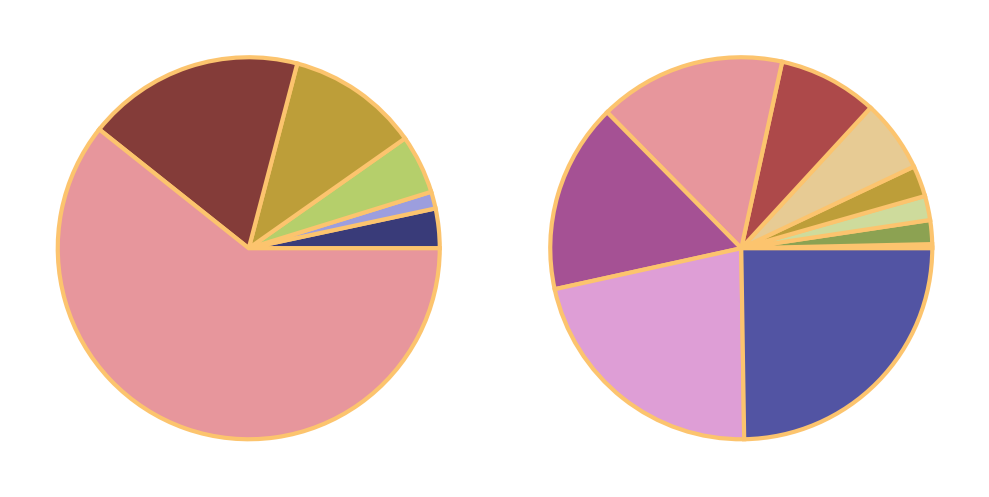

In [111]:
fig,ax = plt.subplots(1,2,figsize=(10,10))
val = df.groupby(['Country']).size().sort_values().values
idx = df.groupby(['Country']).size().sort_values().index
select = val>2000
X0 = np.insert(val[select],0,np.sum(val[~select]))
labels0 = np.insert(idx[select],0,'Other')
X1 = val[~select]
labels1 = idx[~select]
ax[0].pie(X0,colors=tab20b[0:len(tab20b):3],wedgeprops = {'linewidth':2,'edgecolor':[252/255,196/255,110/255]})
ax[1].pie(X1,colors=tab20b[1:len(tab20b)+1:2],wedgeprops = {'linewidth':2,'edgecolor':[252/255,196/255,110/255]})
# ax.legend()
plt.tight_layout()
plt.savefig('Figures/GlobalRx_pie.png',bbox_inches='tight',transparent=True)

In [380]:
df_temp = df[df['Country']!='United States']

In [384]:
df2 = pd.concat([df_temp,US_df])

In [462]:
len(df2)

204517

In [398]:
df2['datestring'] = pd.DatetimeIndex(df2['Date']).strftime('%Y%m%d')

In [461]:
df2.to_csv('Rx_Master/Rx_MASTER_v2024-12-10.csv',index=False)

In [437]:
df2[df2['Country']=='Australia'].groupby(['Country','State/Province']).size()

Country    State/Province    
Australia  New South Wales        7041
           Northern Territory      344
           Queensland             8302
           South Australia        1377
           Tasmania               2067
           Victoria              89576
           Western Australia     11989
dtype: int64

In [457]:
df2[(df2['State/Province']=='New South Wales')&(~np.isinf(df2['RH_min']))]['RH_min'].dropna()

173524    36.361414
173525    63.120950
173526    13.214474
173527    43.902545
173528    43.902545
            ...    
180573    32.329299
180574    46.443108
180575    41.192094
180576    48.122593
180577    71.002389
Name: RH_min, Length: 7041, dtype: float64

#### Map of GlobalRx countries

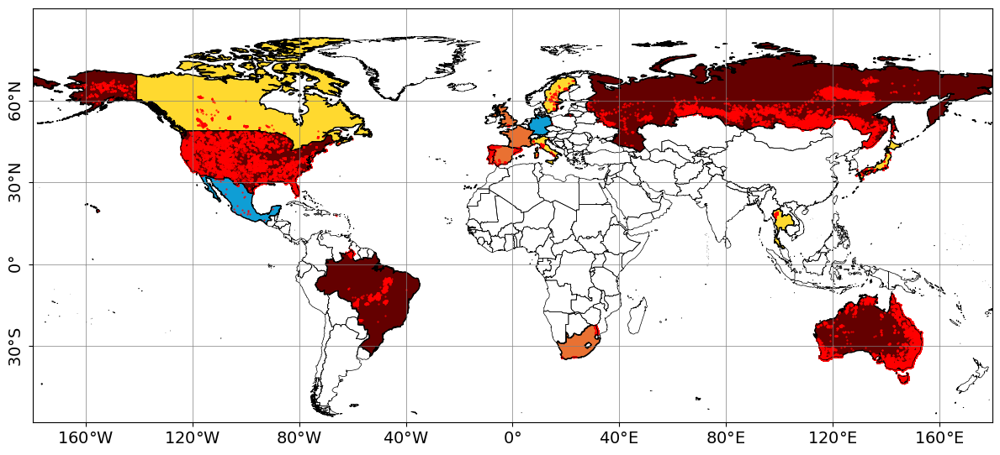

In [386]:
countries = ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'Italy',
       'Japan', 'Mexico', 'Portugal', 'Russian Federation', 'South Africa', 'Spain',
       'Sweden', 'Thailand', 'United States of America', 'U.K. of Great Britain and Northern Ireland']
countries_df = ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'Italy',
       'Japan', 'Mexico', 'Portugal', 'Russia', 'South Africa', 'Spain',
       'Sweden', 'Thailand', 'United States', 'United Kingdom']

fig, ax = plt.subplots(figsize=(12,6))
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')
world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')
bounds = world_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.get_xaxis().set_ticks([])
ax.get_yaxis().set_ticks([])
i=0
for country in countries:
    country_df = countries_df[i]
    i+=1
    country_df = df2[df2['Country']==country_df]
    country_shp = world_shp[world_shp['name']==country]
    if len(country_df)>=5000:
        fclr = [100/255,0,0]
    elif len(country_df)>1000 and len(country_shp)<=4999:
        fclr = [233/255,113/255,50/255]
    elif len(country_df)>100 and len(country_shp)<=999:
        fclr = [255/255,217/255,47/255]
    elif len(country_df)>0 and len(country_shp)<=99:
        fclr = [15/255,158/255,213/255]
    country_shp.plot(ax=ax,facecolor=fclr,edgecolor='Black',aspect='equal',linewidth=1)

ax.scatter(df['Longitude'],df['Latitude'],marker='.',color='r',s=1,label='Burn Records')
world_shp.plot(ax=ax,facecolor='None',edgecolor='Black',linewidth=0.5)

ax.set_xticks([])
ax.set_yticks([])
ax.spines[:].set_visible(True)

xticks = [-160,-120,-80,-40,0,40,80,120,160]
yticks = [-60,-30,0,30,60]
ax.get_xaxis().set_ticks(xticks)
ax.get_yaxis().set_ticks(yticks)
xticklabels = [str(abs(i))+'$\degree$W' if i<0 else str(abs(i))+'$\degree$E' for i in xticks]
xticklabels[4] = '0$\degree$'
yticklabels = [str(abs(i))+'$\degree$S' if i<0 else str(abs(i))+'$\degree$N' for i in yticks]
yticklabels[2] = '0$\degree$'
ax.set_xticklabels(xticklabels,fontsize=14)
ax.set_yticklabels(yticklabels,fontsize=14,rotation=90,rotation_mode='default',va='center')
ax.grid(color='gray',linewidth=0.5)
ax.set_ylim([-58,94]);

# leg = ax.legend(loc='lower left',fontsize=14,handletextpad=0.1)
# leg.legendHandles[0]._sizes = [60]

plt.tight_layout()
plt.savefig('Figures/GlobalRx_record_ct.png',bbox_inches='tight',transparent=True)

#### Map of biomes (using ecoregion shapefile)

In [4]:
in_ax = ax.inset_axes([0.02,0.02,0.3,0.3],transform=ax.transAxes)

country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=in_ax,categories=biomes,aspect='equal')
country_shp.plot(facecolor='none',edgecolor='black',ax=in_ax,aspect='equal')
country_shp[country_shp['ADM1_PT']=='Roraima'].plot(facecolor='none',edgecolor='red',ax=in_ax,aspect='equal')

in_ax.set_xticks([])
in_ax.set_yticks([])
in_ax.grid(visible=True,which='major',axis='both',linewidth=0.5,color=[0.7,0.7,0.7])
in_ax.set_xlim([-63.4,-59])
in_ax.set_ylim([2,6])
ax.indicate_inset_zoom(in_ax,edgecolor='red')

['Boreal Forests/Taiga',
 'Tundra',
 'Deserts & Xeric Shrublands',
 'Mediterranean Forests, Woodlands & Scrub',
 'Montane Grasslands & Shrublands',
 'Flooded Grasslands & Savannas',
 'Temperate Grasslands, Savannas & Shrublands',
 'Tropical & Subtropical Grasslands, Savannas & Shrublands',
 'Temperate Broadleaf & Mixed Forests',
 'Tropical & Subtropical Moist Broadleaf Forests',
 'Tropical & Subtropical Dry Broadleaf Forests',
 'Temperate Conifer Forests',
 'Tropical & Subtropical Coniferous Forests',
 'Mangrove',
 'Lake',
 'Rock/Ice']

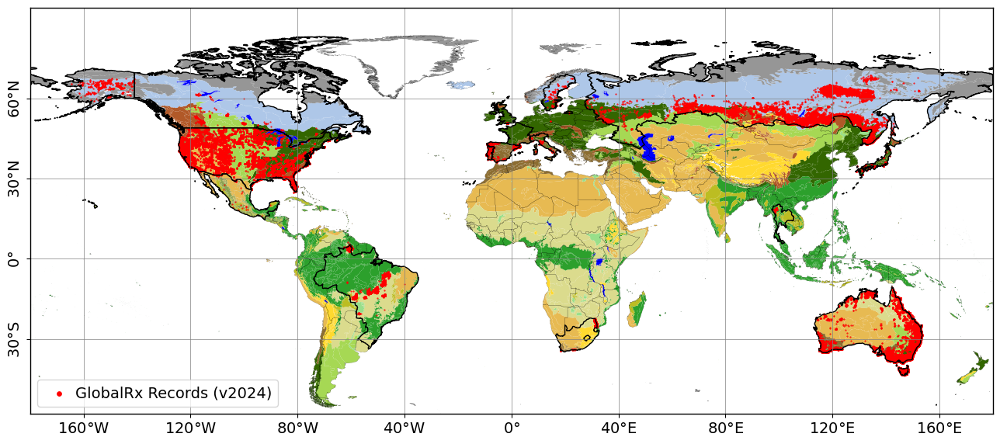

In [44]:
# Set colors for each biome
world_biomes = list(biome_colors.keys())

fig, ax = plt.subplots(figsize=(16,16))
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')

# Display lat/lon
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.spines['left'].set_visible(False)

ax.set_xticks([])
ax.set_yticks([])
ax.spines[:].set_visible(True)

xticks = [-160,-120,-80,-40,0,40,80,120,160]
yticks = [-60,-30,0,30,60]
ax.get_xaxis().set_ticks(xticks)
ax.get_yaxis().set_ticks(yticks)
xticklabels = [str(abs(i))+'$\degree$W' if i<0 else str(abs(i))+'$\degree$E' for i in xticks]
xticklabels[4] = '0$\degree$'
yticklabels = [str(abs(i))+'$\degree$S' if i<0 else str(abs(i))+'$\degree$N' for i in yticks]
yticklabels[2] = '0$\degree$'
ax.set_xticklabels(xticklabels,fontsize=14)
ax.set_yticklabels(yticklabels,fontsize=14,rotation=90,rotation_mode='default',va='center')
ax.grid(color='gray',linewidth=0.5)

eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
for biome in world_biomes:
    eco_shp.loc[eco_shp['BIOME']==biome_dict[biome],'BIOME'] = biome
    
eco_shp.plot(color=eco_shp['BIOME'].map(biome_colors),ax=ax,categories=world_biomes,aspect='equal',edgecolor='None')

# countries = ['Australia','Brazil','Bolivia','Botswana','Canada','China','France','India','Indonesia','Italy',
#              'Japan','Mexico','Namibia','South Africa','Spain','Sweden','United States of America',
#              'U.K. of Great Britain and Northern Ireland','Venezuela','Zambia']

world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')
bounds = world_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]
ax.set_xlim(xlim);
ax.set_ylim([-58,94]);
world_shp.plot(ax=ax,facecolor='None',edgecolor='black',aspect='equal',linewidth=0.1)

ax.scatter(df['Longitude'].values,df['Latitude'].values,color='r',marker='.',s=1,label='GlobalRx Records (v2024)')
leg = ax.legend(loc='lower left',fontsize=14,handletextpad=0.1)
leg.legendHandles[0]._sizes = [60]
countries = ['Australia','Brazil','Canada','France','Italy','Japan','Mexico','Portugal','Russian Federation','South Africa','Spain',
             'Sweden','Thailand','United States of America','U.K. of Great Britain and Northern Ireland']
for country in countries:
    country_shp = world_shp[world_shp['name']==country]
    country_shp.plot(ax=ax,facecolor='None',edgecolor='Black',aspect='equal',linewidth=1)
plt.savefig('Figures/GlobalRx_countries_biomes.png',bbox_inches='tight',transparent=True)


In [31]:
biome_colors = {'Boreal Forests/Taiga': (0.6823529411764706,0.7803921568627451,0.9098039215686274),
 'Tundra': (0.95,0.95,0.95,0.3),
 'Deserts & Xeric Shrublands': (0.9058823529411765,0.7294117647058823,0.3215686274509804),
 'Mediterranean Forests, Woodlands & Scrub': (0.5490196078431373,0.42745098039215684,0.19215686274509805),
 'Montane Grasslands & Shrublands': (1.0,0.8509803921568627,0.1843137254901961),
 'Flooded Grasslands & Savannas': (0.596078431372549,0.8745098039215686,0.5411764705882353),
 'Temperate Grasslands, Savannas & Shrublands': (0.6509803921568628,0.8470588235294118,0.32941176470588235),
 'Tropical & Subtropical Grasslands, Savannas & Shrublands': (0.8588235294117647,0.8588235294117647,0.5529411764705883),
 'Temperate Broadleaf & Mixed Forests': (0.2, 0.4, 0),
 'Tropical & Subtropical Moist Broadleaf Forests': (0.17254901960784313,0.6274509803921569,0.17254901960784313),
 'Tropical & Subtropical Dry Broadleaf Forests': (0.7372549019607844,0.7411764705882353,0.13333333333333333),
 'Temperate Conifer Forests': (0.6941176470588235,0.34901960784313724,0.1568627450980392),
 'Tropical & Subtropical Coniferous Forests': (0.5490196078431373,0.6352941176470588,0.3215686274509804),
 'Mangrove': [0.8,0.8,0.8,0.3],
 'Lake': [0.8,0.8,0.8,0.3],
 'Rock/Ice': [0.95,0.95,0.95,0.3]}

<AxesSubplot:>

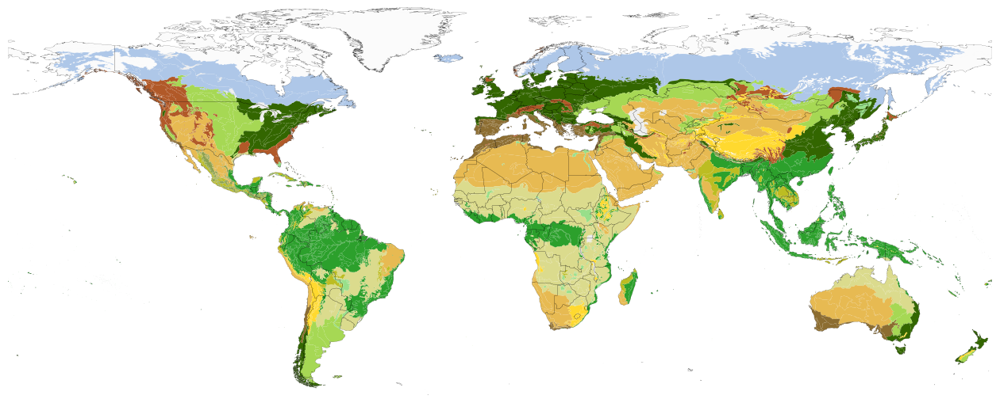

In [32]:
fig,ax = plt.subplots(1,1,figsize=(16,16))
world_biomes = list(biome_colors.keys())

eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
for biome in world_biomes:
    eco_shp.loc[eco_shp['BIOME']==biome_dict[biome],'BIOME'] = biome

eco_shp.plot(color=eco_shp['BIOME'].map(biome_colors),ax=ax,categories=world_biomes,aspect='equal')

world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')
bounds = world_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]
ax.set_xlim(xlim);
ax.set_ylim(ylim);

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

# ax.scatter(IFM_df['Longitude'].values,IFM_df['Latitude'].values,marker='o',color='k',s=10)
world_shp.plot(ax=ax,facecolor='None',edgecolor='black',aspect='equal',linewidth=0.1)
# i = 0
# for idx in IFM_df.index:
#     i+=1
#     lon = float(IFM_df.loc[idx,'Longitude'])
#     lat = float(IFM_df.loc[idx,'Latitude'])
# #     country = IFM_df.loc[idx,'Country']
#     continent = IFM_df.loc[idx,'Continent']
#     cont_shp = conts_shp['geometry'][conts_shp['CONTINENT']==continent].iloc[0]
# #     world_shp['geometry'][world_shp['name']==country].iloc[0]
# #     x,y = closest_vertex_shapely(cont_shp,(lon,lat))
#     x = lon
#     y = lat
# #     offsetbox = TextArea(IFM_df.loc[idx,'IFM Objectives'])
#     offsetbox = TextArea(str(i))
#     ab = AnnotationBbox(offsetbox,(lon,lat),
#                         xybox=(x,y),
#                         xycoords='data',
#                         boxcoords=("data"),
#                         box_alignment=(0.,0),
#                         arrowprops=dict(arrowstyle="-"))
#     ax.add_artist(ab)
# ax.scatter(101.223075,25.928150,marker='o',color='red')
# plt.savefig('IFM_countries_outlined_biomes.png',bbox_inches='tight',transparent=True)

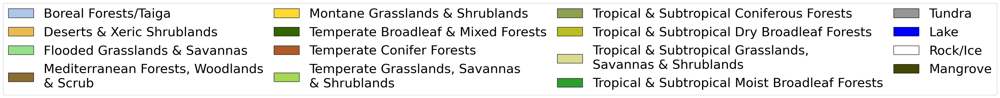

In [38]:
legend_elements = []
for biome in biome_dict.keys():
    if biome == 'Mediterranean Forests, Woodlands & Scrub':
        biome_label = 'Mediterranean Forests, Woodlands\n& Scrub'
        legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
        continue
    if biome == 'Temperate Grasslands, Savannas & Shrublands':
        biome_label = 'Temperate Grasslands, Savannas\n& Shrublands'
        legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
        continue
    if biome == 'Tropical & Subtropical Dry Broadleaf Forests':
        biome_label = 'Tropical & Subtropical Dry Broadleaf Forests'
        legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
        continue
    if biome == 'Tropical & Subtropical Grasslands, Savannas & Shrublands':
        biome_label = 'Tropical & Subtropical Grasslands,\nSavannas & Shrublands'
        legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
        continue
#     if biome == 'Tropical & Subtropical Moist Broadleaf Forests':
#         biome_label = 'Tropical & Subtropical Moist Broadleaf Forests'
#         legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
#         continue
    else: 
        biome_label = biome
        legend_elements.append(Patch(facecolor=biome_colors[biome],edgecolor='Black',label=biome_label))
    
# legend_elements.append(Patch.Circle(fill_color='red',edgecolor='Black',label='GlobalRx (v2024)'))
    
fig, ax = plt.subplots(figsize=(1,1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.get_xaxis().set_ticks([])
ax.get_yaxis().set_ticks([])

n = 4
ax.legend(handles=legend_elements,loc='center',fontsize=30,framealpha=1,
          ncol=4,columnspacing=0.8,facecolor=(1,1,1,0))
plt.savefig('Figures/GlobalRx_countries_biomes_legend_'+str(n)+'col.png',bbox_inches='tight',transparent=True)

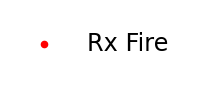

In [33]:
fig, ax = plt.subplots(figsize=(1,1))
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.get_xaxis().set_ticks([])
ax.get_yaxis().set_ticks([])
ax.scatter(0,100,color='Red',s=50,marker='o',label='Rx Fire')
ax.legend(fontsize='xx-large',loc='upper right',framealpha=0)
plt.savefig('Rx_fire_leg.png',bbox_inches='tight',transparent=True)

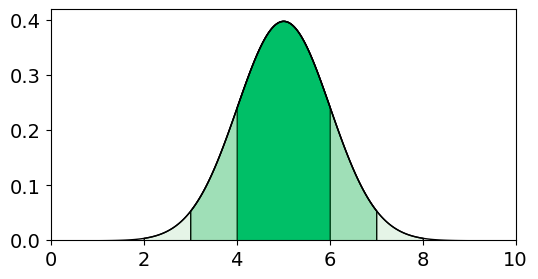

In [5]:
fig, ax = plt.subplots(figsize=(6,3))

mu = 5
variance = 1
sigma = variance**0.5
x1 = np.linspace(mu - 1*sigma, mu + 1*sigma, 1000)
x2 = np.linspace(mu - 2*sigma, mu + 2*sigma, 1000)
x3 = np.linspace(mu - 3*sigma, mu + 3*sigma, 1000)
x4 = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
ax.fill_between(x1,np.zeros(np.shape(x1)),scipy.stats.norm.pdf(x1, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.8,0.5,1])
ax.fill_between(x2,np.zeros(np.shape(x2)),scipy.stats.norm.pdf(x2, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.7,0.3,0.3])
ax.fill_between(x3,np.zeros(np.shape(x3)),scipy.stats.norm.pdf(x3, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.6,0.1,0.1])
ax.fill_between(x4,np.zeros(np.shape(x4)),scipy.stats.norm.pdf(x4, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,1,0,0])
ax.set_ylim([0,0.42])
ax.set_xlim([0,10])
ax.tick_params(axis='both',which='major',labelsize=14)
# plt.savefig('theoretical_FWI.png',bbox_inches='tight')

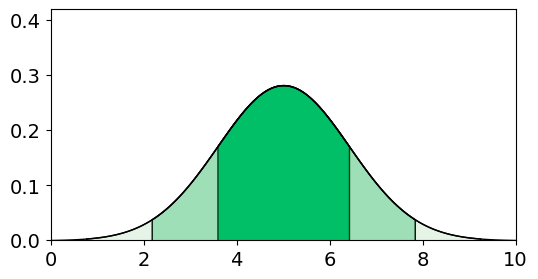

In [6]:
fig, ax = plt.subplots(figsize=(6,3))

mu = 5
variance = 2
sigma = variance**0.5
x1 = np.linspace(mu - 1*sigma, mu + 1*sigma, 1000)
x2 = np.linspace(mu - 2*sigma, mu + 2*sigma, 1000)
x3 = np.linspace(mu - 3*sigma, mu + 3*sigma, 1000)
x4 = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
ax.fill_between(x1,np.zeros(np.shape(x1)),scipy.stats.norm.pdf(x1, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.8,0.5,1])
ax.fill_between(x2,np.zeros(np.shape(x2)),scipy.stats.norm.pdf(x2, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.7,0.3,0.3])
ax.fill_between(x3,np.zeros(np.shape(x3)),scipy.stats.norm.pdf(x3, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,0.6,0.1,0.1])
ax.fill_between(x4,np.zeros(np.shape(x4)),scipy.stats.norm.pdf(x4, mu, sigma),edgecolor=[0,0,0,1],facecolor=[0,1,0,0])
ax.set_ylim([0,0.42])
ax.set_xlim([0,10])
ax.tick_params(axis='both',which='major',labelsize=14)
# plt.savefig('theoretical_FWI.png',bbox_inches='tight')

In [102]:
def skew_norm_pdf(x,location,scale,a):
    # adapated from:
    # http://stackoverflow.com/questions/5884768/skew-normal-distribution-in-scipy
    t = (x-location) / scale
    y = 2.0 * scale*scipy.stats.norm.pdf(t) * scipy.stats.norm.cdf(a*t)
    return y

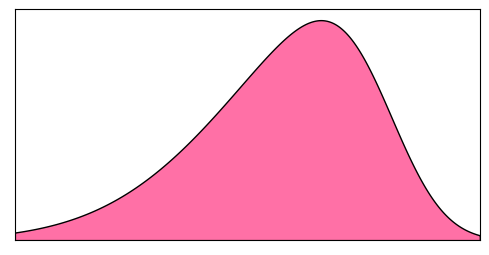

In [150]:
x = np.linspace(0,10,1000)

scale = 3
r = [0.2,0.2,1,0]
g = [1,0,0.2,0.5]
b = [0,0.2,0.5,1]
i=0
for a in [-3]:
    i=2
    if a<0:
        location=8
    else:
        location=3
    y = skew_norm_pdf(x,location,scale,a)

    fig, ax = plt.subplots(figsize=(6,3))
    ax.fill_between(x,np.zeros(np.shape(x)),y,edgecolor=[0,0,0,1],facecolor=[r[i],g[i],b[i],0.7])
    ax.set_ylim(bottom=0)
    ax.set_xlim([0,10])
    ax.set_xticks([])
    ax.set_yticks([])
    plt.savefig('theoretical_skew_a'+str(a)+'_loc'+str(location)+'sc'+str(scale)+'rgB'+str(b[i])+'.png',bbox_inches='tight')
    